# Librerías y Funciones

In [1]:
import uproot as up
import awkward as ak
import matplotlib.pyplot as plt
import vector as vec
import numpy as np
import pandas as pd
import os
from pathlib import Path
from scipy import stats as st
from matplotlib.ticker import MultipleLocator, FuncFormatter
from matplotlib.colors import LogNorm

vec.register_awkward()

In [2]:
# Funciones

# Utilitary functions

def pi_formatter(x, pos):
    n = x / np.pi
    if np.isclose(n, 0):
        return r"$0$"
    if np.isclose(n, 1):
        return r"$\pi$"
    if np.isclose(n, -1):
        return r"$-\pi$"
    if n.is_integer():
        return rf"${int(n)}\pi$"
    return rf"${int(2*n)}\pi/2$"

def print_sample_info(Delphes, Energy_label, Gen_Events, Process, data_to_analyse, N_data):

    print("┌─────────────────────────────────────┐")
    print("│           SAMPLE INFORMATION        │")
    print("├─────────────────────────────────────┤")
    print(f"│ Delphes       : {Delphes:<20}│")
    print(f"│ Energy        : {Energy_label:<20}│")
    print(f"│ Gen. Events   : {Gen_Events:<20}│")
    print(f"│ Proc. Events  : {N_data:<20}│")
    print(f"│ Process       : {Process:<20}│")
    print("├─────────────────────────────────────┤")
    print(f"│ Dataset       : {data_to_analyse:<20}│")
    print("└─────────────────────────────────────┘")

def parse_events(s):
    s = s.strip().lower()
    mult = {"k": 1_000, "M": 1_000_000}
    if s[-1] in mult:
        return int(float(s[:-1]) * mult[s[-1]])
    return int(s)

def calculo_rangos(lim_inf, lim_sup, data):

    if type(data) == list:

        Gen_Events = sum(len(data_i) for data_i in data)

        debajo = sum(np.sum(data_i < lim_inf) for data_i in data)

        dentro = sum(
            np.sum((data_i >= lim_inf) & (data_i <= lim_sup))
            for data_i in data
        )

        encima = sum(np.sum(data_i > lim_sup) for data_i in data)

        p_debajo = 100 * debajo / Gen_Events
        p_dentro = 100 * dentro / Gen_Events
        p_encima = 100 * encima / Gen_Events

        return lim_inf, lim_sup, p_debajo, p_dentro, p_encima

    else:

        return print("Error: data debe ser una lista de arrays de datos.")

# Selection Functions

def MET_trigger(data, MET_lowerbond):

    MET_mask = ak.flatten(data["MissingET.MET"]) > MET_lowerbond

    return MET_mask

def preselection_cut(vec, Pt_lowerBond, Eta_absoluteBond):
    cinematic_mask = (vec.pt > Pt_lowerBond) & (abs(vec.eta) < Eta_absoluteBond)
    return cinematic_mask


def vectors_buildup(data):

    jets = ak.zip({
        "pt": data["Jet.PT"],
        "eta": data["Jet.Eta"],
        "phi": data["Jet.Phi"],
        "mass": data["Jet.Mass"],
        'TauTag': data["Jet.TauTag"],
        'BTag': data["Jet.BTag"],
    }, with_name="Momentum4D")

    tracks = ak.zip({"pt": data["Track.PT"], "eta": data["Track.Eta"],
                    "phi": data["Track.Phi"],
                    "mass": ak.zeros_like(data["Track.PT"]),
                    "charge": data["Track.Charge"],
                    "d0":  data["Track.D0"],
                    "dz":  data["Track.DZ"]},
                    with_name="Momentum4D")

    return jets, tracks


def Selected_data(data, MET_LB, PT_LB_jets, Eta_AB_jets, PT_LB_tracks, Eta_AB_tracks):
    MET_mask = MET_trigger(data, MET_LB)
    data_selected = data[MET_mask]

    jets, tracks = vectors_buildup(data_selected)

    jets_select   = jets[preselection_cut(jets,   PT_LB_jets,   Eta_AB_jets)]
    tracks_select = tracks[preselection_cut(tracks, PT_LB_tracks, Eta_AB_tracks)]

    return jets_select, tracks_select, MET_mask   

def Taus_and_bjets(jets):
    taus = jets[(jets['TauTag'] == 1) & (jets['BTag'] == 0)]
    bjets = jets[(jets['TauTag'] == 0) & (jets['BTag'] == 1)]

    N_events = len(ak.sum(jets, axis=1))
    N_taus = ak.num(taus, axis=1)
    N_bjets = ak.num(bjets, axis=1)

    return taus, bjets, N_events, N_taus, N_bjets

def kinematic_hierarchical_order(taus, bjets):
    mask  = (ak.num(taus) >= 2) & (ak.num(bjets) >= 2)
    taus_cut, bjets_cut = taus[mask], bjets[mask]
    tau1, tau2 = taus_cut[:,0], taus_cut[:,1]
    b1, b2     = bjets_cut[:,0], bjets_cut[:,1]
    return tau1, tau2, b1, b2, taus_cut, bjets_cut

def PT_and_IM_of_products(tau1, tau2, b1, b2):
    
    h_tautau_vec = tau1+tau2
    h_bb_vec = b1+b2
    
    M_tautau = h_tautau_vec.mass
    M_bb     = h_bb_vec.mass
    M_hh     = (tau1+tau2+b1+b2).mass

    PT_tautau = h_tautau_vec.pt
    PT_bb     = h_bb_vec.pt
    PT_hh     = (tau1+tau2+b1+b2).pt

    tuple_tautau = (M_tautau, PT_tautau)
    tuple_bb = (M_bb, PT_bb)
    tuple_hh = (M_hh, PT_hh)

    return tuple_tautau, tuple_bb, tuple_hh

# Data

In [ ]:
common_path_of_data = "/home/usuario/Madgraph/projects/"
saving_path = '/home/usuario/VSCode/diHiggs-Project/RecAnalysis/'

Delphes = "HL-LHC"
Energy_label = "14TeV"
BenchMark = "Pruebas"
process = "gg-hhj"

rutas = {
    'signal': "/home/usuario/Madgraph/projects/gg_hh-LQs/plusjet/output_ggHH_bbtata_BP1_80_0_delphes_events.root",
#    'bkg': "/home/usuario/Madgraph/projects/pp_tthj-1800k_reduced/output_pp_tthj_h-tata_1800k_104_0_delphes_events.root",
}

data_to_analyse = f"{Delphes}_{Energy_label}_{BenchMark}_{process}"

reco_keys = ["Jet.PT", "Jet.Eta", "Jet.Phi", "Jet.Mass", "Jet.BTag", "Jet.TauTag",
             "MissingET.MET",
             "Track.PT", "Track.Eta", "Track.Phi", "Track.DZ", "Track.D0", "Track.Charge"]

truth_keys = ["Particle.PID", "Particle.Status",
              "Particle.Px", "Particle.Py", "Particle.Pz", "Particle.E",
              "Particle.X", "Particle.Y", "Particle.Z"]


def load_truth_taus(path, step_size="500 MB"):
    """Lee Particle por lotes y conserva solo los taus (status 2),
    con su cuadrivector cartesiano y su vertice."""
    trozos = []
    for batch in up.iterate(f"{path}:Delphes", truth_keys, step_size=step_size):
        es_tau = (abs(batch["Particle.PID"]) == 15) & (batch["Particle.Status"] == 2)
        trozos.append(ak.zip({
            "px":  batch["Particle.Px"][es_tau],
            "py":  batch["Particle.Py"][es_tau],
            "pz":  batch["Particle.Pz"][es_tau],
            "E":   batch["Particle.E"][es_tau],
            "pid": batch["Particle.PID"][es_tau],
            "status": batch["Particle.Status"][es_tau],
            "vx":  batch["Particle.X"][es_tau],
            "vy":  batch["Particle.Y"][es_tau],
            "vz":  batch["Particle.Z"][es_tau],
        }, with_name="Momentum4D"))
    return ak.concatenate(trozos)


def data_loader(rutas):
    reco  = {k: up.concatenate(f"{p}:Delphes", reco_keys) for k, p in rutas.items()}
    truth = {k: load_truth_taus(p) for k, p in rutas.items()}
    return reco, truth


all_data, truth_taus = data_loader(rutas)

N_data = len(all_data['signal'])

data_to_analyse = f"{Delphes}_{Energy_label}_{BenchMark}_{process}"

print_sample_info(Delphes, Energy_label, BenchMark, process, data_to_analyse, N_data)

os.makedirs(saving_path, exist_ok=True)

┌─────────────────────────────────────┐
│           SAMPLE INFORMATION        │
├─────────────────────────────────────┤
│ Delphes       : HL-LHC              │
│ Energy        : 14TeV               │
│ Gen. Events   : Pruebas             │
│ Proc. Events  : 9736                │
│ Process       : gg-hhj              │
├─────────────────────────────────────┤
│ Dataset       : HL-LHC_14TeV_Pruebas_gg-hhj│
└─────────────────────────────────────┘


# MET and Kinematic cuts

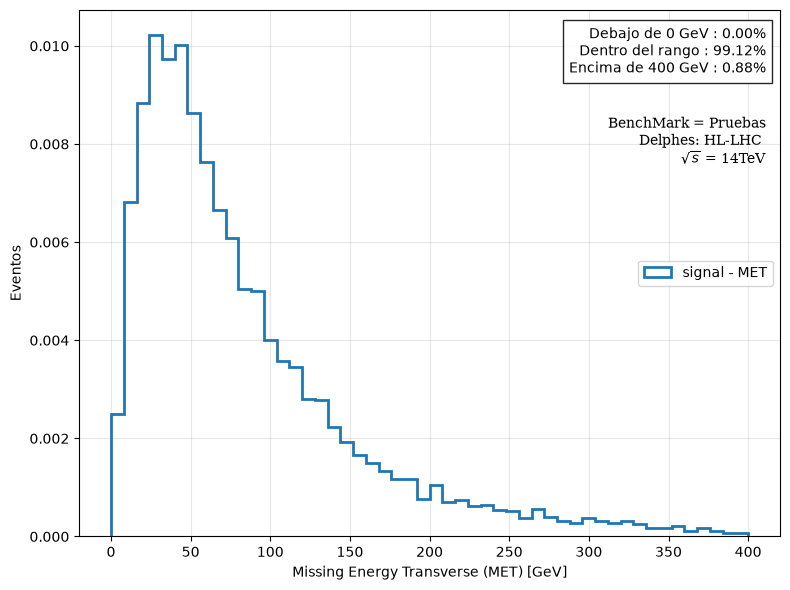

In [49]:
# Distribucion de MET, solo con corte de Cinemática

MET_data = {key: all_data[key]["MissingET.MET"] for key in all_data}

lim_inf, lim_sup, p_debajo, p_dentro, p_encima = calculo_rangos(0,400, list(MET_data.values()))

Data_text_ID_precut = ( fr"BenchMark = {BenchMark}" "\n"
                        fr"Delphes: {Delphes} " "\n"
                        r"$\sqrt{s}$" f" = {Energy_label}")

plt.figure(figsize=(8,6))

texto = (f"Debajo de {lim_inf} GeV : {p_debajo:.2f}%\n"f"Dentro del rango : {p_dentro:.2f}%\n"f"Encima de {lim_sup} GeV : {p_encima:.2f}%")
plt.text(0.98, 0.97,texto,transform=plt.gca().transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))

plt.text(0.98, 0.8, Data_text_ID_precut, transform=plt.gca().transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

for i, (key, MET) in enumerate(MET_data.items()):
        plt.hist(MET, bins=50, density=True, range=(lim_inf, lim_sup), histtype="step", linewidth=2, label=f"{key} - MET")

plt.xlabel(r"Missing Energy Transverse (MET) [GeV]")
plt.ylabel("Eventos")
plt.legend(loc = 'center right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{saving_path}/{data_to_analyse}/MET_distribution.png", dpi=300)
plt.show()

In [50]:
# Parámetros a definir

# [0, 20, 50, 70, 100, 150]

MET_LowerBond = 100     # GeV

# Jets preselection cuts
Pre_PT_jet = 20       # GeV
Pre_eta_jet = 2.5

# Tracks preselection cuts
Pre_PT_track = 0      # GeV
Pre_eta_track = 2.5

selected_data_folder_path_truth = f"{saving_path}/{data_to_analyse}/Truth/MET{MET_LowerBond}_PT{Pre_PT_jet}_Eta{Pre_eta_jet}"
selected_data_folder_path_jets = f"{saving_path}/{data_to_analyse}/Jets/MET{MET_LowerBond}_PT{Pre_PT_jet}_Eta{Pre_eta_jet}"
selected_data_folder_path_tracks = f"{saving_path}/{data_to_analyse}/Tracks/MET{MET_LowerBond}_PT{Pre_PT_track}_Eta{Pre_eta_track}"

Data_text_ID_jets = ("BenchMark: " f"{BenchMark}" "\n"
                f"Process: {process}" "\n"
                fr"Delphes: {Delphes}" "\n"
                r"$\sqrt{s}$" f" = {Energy_label}" "\n"
                fr"MET > {MET_LowerBond} GeV" "\n"
                fr"$p_T$ > {Pre_PT_jet} GeV" "\n"
                rf"$|\eta| < {Pre_eta_jet}$")

Data_text_ID_tracks = ("BenchMark: " f"{BenchMark}" "\n"
                    f"Process: {process}" "\n"
                    fr"Delphes: {Delphes}" "\n"
                    r"$\sqrt{s}$" f" = {Energy_label}" "\n"
                    fr"MET > {MET_LowerBond} GeV" "\n"
                    fr"$p_T$ > {Pre_PT_track} GeV" "\n"
                    rf"$|\eta| < {Pre_eta_track}$")


os.makedirs(selected_data_folder_path_truth, exist_ok=True)
os.makedirs(selected_data_folder_path_jets, exist_ok=True)
os.makedirs(selected_data_folder_path_tracks, exist_ok=True)

def build_objects(data, truth, MET_LowerBond, Pre_PT_jet, Pre_eta_jet,
                  Pre_PT_track, Pre_eta_track):
    jets, tracks, gen = {}, {}, {}
    for key, d in data.items():
        jets[key], tracks[key], MET_mask = Selected_data(
            d, MET_LowerBond, Pre_PT_jet, Pre_eta_jet, Pre_PT_track, Pre_eta_track)
        gen[key] = truth[key][MET_mask]      # mismo corte que los tracks
    return jets, tracks, gen

jets, tracks, gen = build_objects(all_data, truth_taus, MET_LowerBond,
                                  Pre_PT_jet, Pre_eta_jet,
                                  Pre_PT_track, Pre_eta_track)


# Truth Analysis

In [ ]:
taus_finales = 

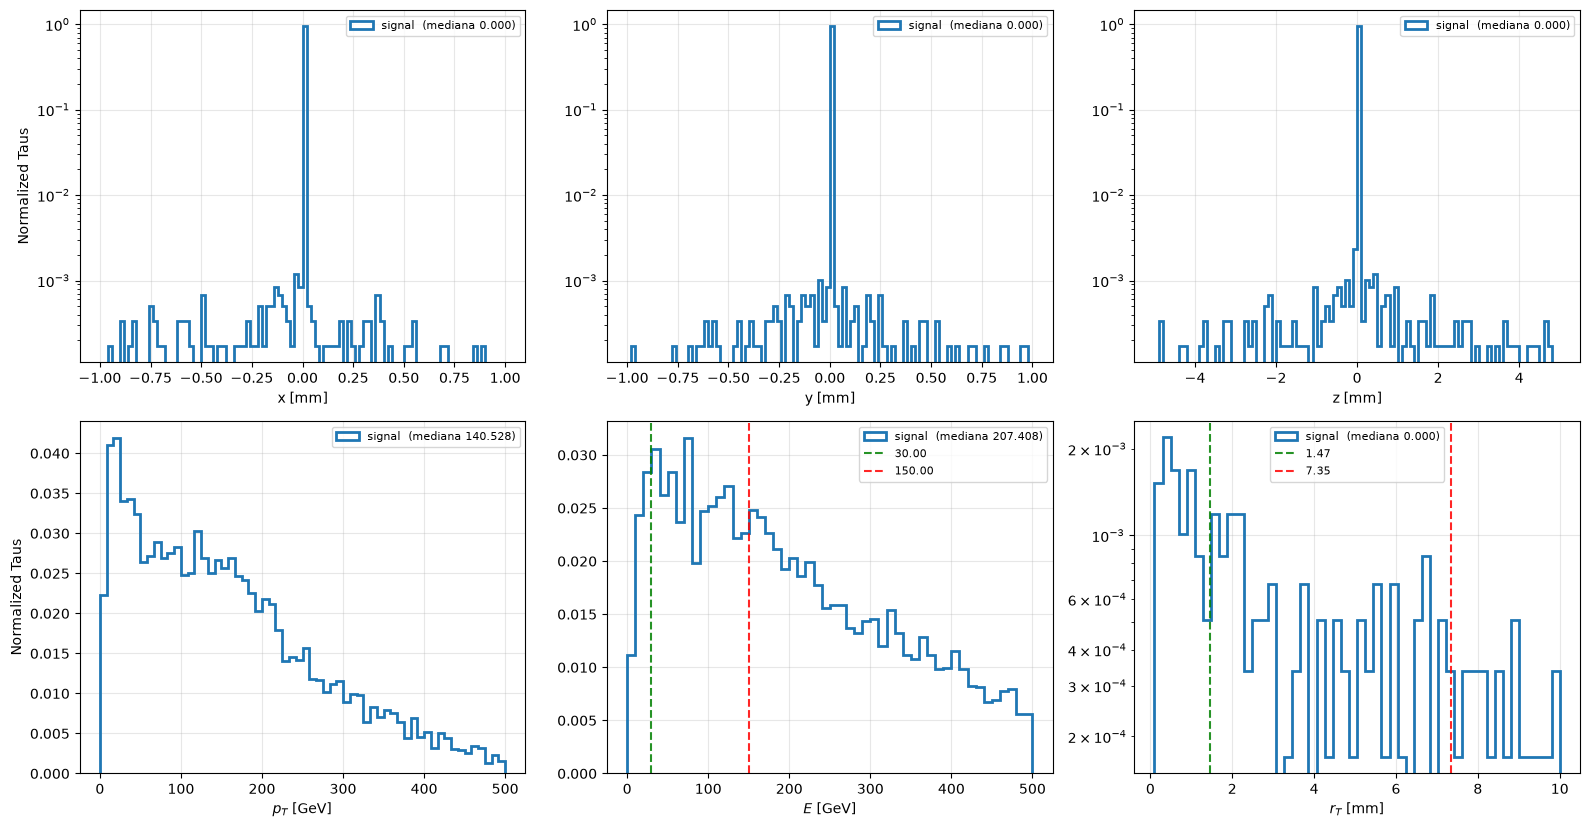

In [20]:
# Selecciono los taus finales que decaen:

taus_gen = {key: gen[key][(abs(gen[key].pid) == 15) & (gen[key].status == 2)] for key in gen}
TwoTaus_gen = {key: taus_gen[key][(ak.num(taus_gen[key], axis=1) >= 2)] for key in taus_gen}

n_taus_per_event = {key: ak.num(TwoTaus_gen[key], axis=1) for key in TwoTaus_gen}
n_total = {key: ak.sum(n_taus_per_event[key]) for key in n_taus_per_event}

# Una entrada por tau, para cada variable
PT_taus_to_decay = {key: ak.to_numpy(ak.flatten(t.pt)) for key, t in TwoTaus_gen.items()}
E_taus_to_decay  = {key: ak.to_numpy(ak.flatten(t.E))  for key, t in TwoTaus_gen.items()}
X_vertex = {key: ak.to_numpy(ak.flatten(t.vx)) for key, t in TwoTaus_gen.items()}
Y_vertex = {key: ak.to_numpy(ak.flatten(t.vy)) for key, t in TwoTaus_gen.items()}
Z_vertex = {key: ak.to_numpy(ak.flatten(t.vz)) for key, t in TwoTaus_gen.items()}
RT_vertex = {key: np.sqrt(X_vertex[key]**2 + Y_vertex[key]**2 + Z_vertex[key]**2) for key in X_vertex}

# ---- vlines ----
CTAU  = 0.08703      # mm, ctau del tau
M_TAU = 1.77686      # GeV

def r_de_E(E):
    """Distancia de decaimiento media de un tau de energia E: gamma*beta*c*tau."""
    gamma = E / M_TAU
    beta  = np.sqrt(1 - 1 / gamma**2)
    return gamma * beta * CTAU

E_VERDE, E_ROJO = 30.0, 150.0        # GeV

VLINES = {
    r"$E$ [GeV]":  [(E_VERDE, "green"), (E_ROJO, "red")],
    r"$r_T$ [mm]": [(r_de_E(E_VERDE), "green"), (r_de_E(E_ROJO), "red")],
}

# (datos, etiqueta del eje x, rango, nbins, escala log en y)
paneles = [
    (X_vertex,         "x [mm]",       (-1, 1), 100, True),
    (Y_vertex,         "y [mm]",       (-1, 1), 100, True),
    (Z_vertex,         "z [mm]",       (-5, 5), 100, True),
    (PT_taus_to_decay, r"$p_T$ [GeV]", (0, 500),  60, False),
    (E_taus_to_decay,  r"$E$ [GeV]",   (0, 500),  50, False),
    (RT_vertex,        r"$r_T$ [mm]",  (0.1, 10),   50, True),
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, (datos, xlab, rango, nbins, logy) in zip(axes.flat, paneles):
    for k, a in datos.items():
        w = np.full(len(a), 1.0 / n_total[k])
        ax.hist(a, bins=nbins, range=rango, weights=w,
                histtype="step", linewidth=2,
                label=f"{k}  (mediana {np.median(a):.3f})")

    for valor, color in VLINES.get(xlab, []):
        ax.axvline(valor, color=color, ls="--", lw=1.5, alpha=0.85,
                   label=f"{valor:.2f}")

    if logy:
        ax.set_yscale("log")
    ax.set_xlabel(xlab)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)

axes[0, 0].set_ylabel("Normalized Taus")
axes[1, 0].set_ylabel("Normalized Taus")

fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(f"{selected_data_folder_path_truth}/Tau_decay_vertex.png", dpi=300)
plt.show()

# Tracks Analysis

In [21]:
def match_tracks_to_truth_taus(gen_ev, tracks_ev, dr_tau=0.2, pt_track=1):
    trk = tracks_ev[tracks_ev.pt > pt_track]

    t2 = gen_ev[(abs(gen_ev.pid) == 15) & (gen_ev.status == 2)]
    tm_all, tp_all = t2[t2.pid > 0], t2[t2.pid < 0]

    ok = (ak.num(tm_all, axis=1) >= 1) & (ak.num(tp_all, axis=1) >= 1)
    tm, tp, trk = tm_all[ok], tp_all[ok], trk[ok]

    # el tau del Higgs es el duro; los extra son secundarios del shower (hadrones B)
    taum = tm[ak.argmax(tm.pt, axis=1, keepdims=True)][:, 0]
    taup = tp[ak.argmax(tp.pt, axis=1, keepdims=True)][:, 0]

    en_m = taum.deltaR(trk) < dr_tau
    en_p = taup.deltaR(trk) < dr_tau

    return {"taum": taum, "taup": taup, "tracks": trk,
            "en_taum": en_m, "en_taup": en_p,
            "tracks_taum": trk[en_m], "tracks_taup": trk[en_p],
            "tracks_taus": trk[en_m | en_p],
            "n_m": ak.num(trk[en_m], axis=1),
            "n_p": ak.num(trk[en_p], axis=1),
            "ok": ok}

signal: ok 2821/2821  prongs- [ 236 2073  233  218   34]  prongs+ [ 266 2053  249  205   22]


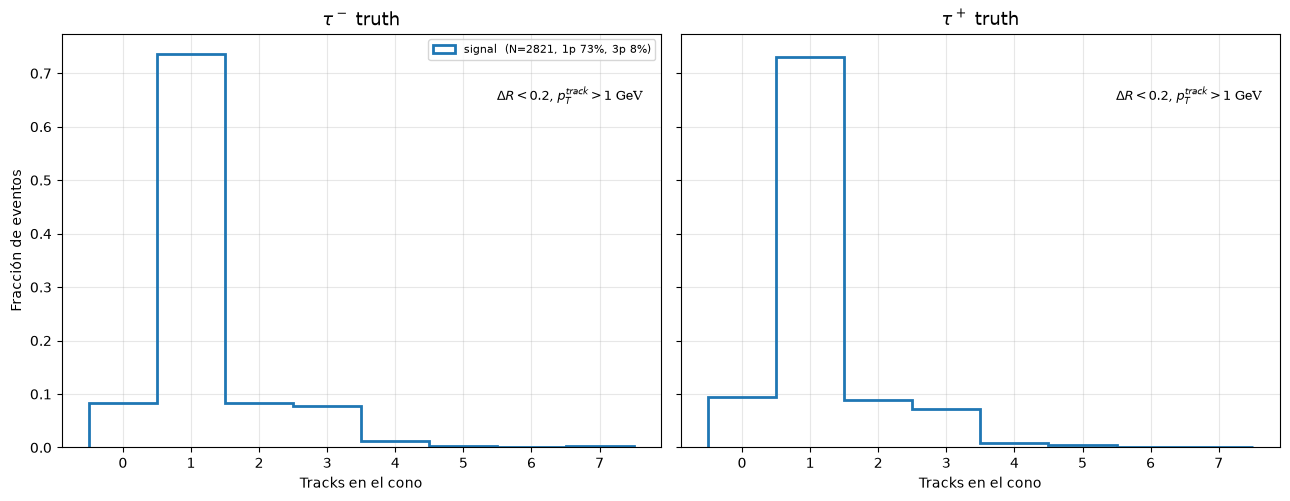

In [22]:
# ---- parámetros ----
DR_TAU   = 0.2    # radio del cono alrededor del tau truth
PT_TRACK = 1    # umbral mínimo de pT de los tracks [GeV]

Tracks_truthTaus = {key: match_tracks_to_truth_taus(gen[key], tracks[key]) for key in gen}

for key, m in Tracks_truthTaus.items():
    print(f"{key}: ok {ak.sum(m['ok'])}/{len(m['ok'])}  "
          f"prongs- {np.bincount(ak.to_numpy(m['n_m']), minlength=5)[:5]}  "
          f"prongs+ {np.bincount(ak.to_numpy(m['n_p']), minlength=5)[:5]}")

bines = np.arange(-0.5, 8.5, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for ax, campo, lab in [(axes[0], "n_m", r"$\tau^-$ truth"),
                       (axes[1], "n_p", r"$\tau^+$ truth")]:
    for key, m in Tracks_truthTaus.items():
        a = ak.to_numpy(m[campo])
        ax.hist(a, bins=bines, histtype="step", linewidth=2, density=True,
                label=f"{key}  (N={len(a)}, 1p {100*(a==1).mean():.0f}%, "
                      f"3p {100*(a==3).mean():.0f}%)")
        
    ax.text(0.97, 0.87, fr"$\Delta R < {DR_TAU}$, $p_T^{{track}} > {PT_TRACK}$ GeV",
         ha="right", va="top", fontsize=9, family="DejaVu Serif", transform=ax.transAxes)
    ax.set_title(lab, fontsize=13)
    ax.set_xlabel("Tracks en el cono")
    ax.set_xticks(range(0, 8))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Fracción de eventos")
axes[0].legend(fontsize=8, loc="upper right")

plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(f"{selected_data_folder_path_tracks}/Prongs_truth_matched.png", dpi=300)
plt.show()

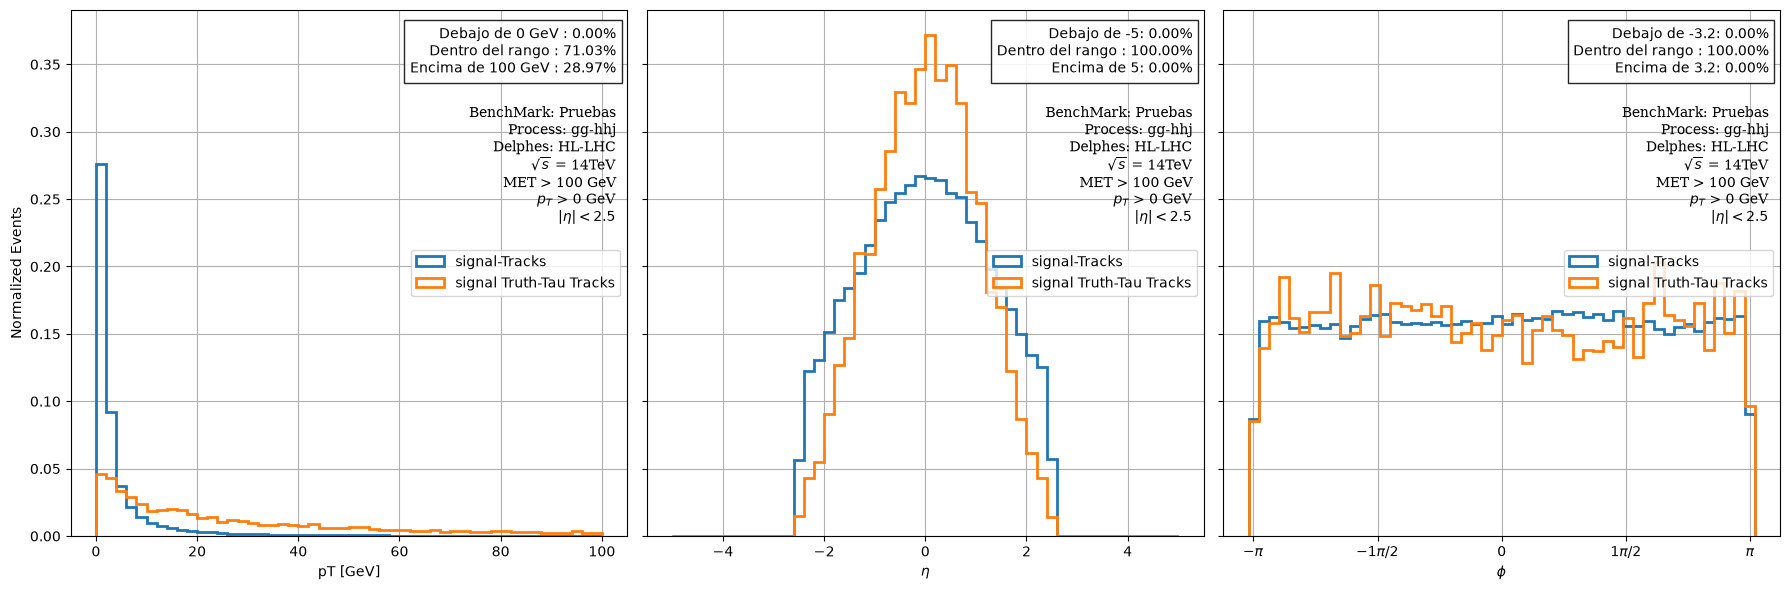

In [23]:
pt_data = {key: ak.to_numpy(ak.flatten(tracks[key].pt)) for key in tracks}
eta_data = {key: ak.to_numpy(ak.flatten(tracks[key].eta)) for key in tracks}
phi_data = {key: ak.to_numpy(ak.flatten(tracks[key].phi)) for key in tracks}

pt_data_taus = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].pt)) for key in Tracks_truthTaus}
eta_data_taus = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].eta)) for key in Tracks_truthTaus}
phi_data_taus = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].phi)) for key in Tracks_truthTaus}

lim_inf_pt, lim_sup_pt, p_debajo_pt, p_dentro_pt, p_encima_pt = calculo_rangos(0, 100, list(MET_data.values()))
lim_inf_eta, lim_sup_eta, p_debajo_eta, p_dentro_eta, p_encima_eta = calculo_rangos(-5,5, list(eta_data.values()))
lim_inf_phi, lim_sup_phi, p_debajo_phi, p_dentro_phi, p_encima_phi = calculo_rangos(-3.2,3.2, list(phi_data.values()))

texto_pt = (f"Debajo de {lim_inf_pt} GeV : {p_debajo_pt:.2f}%\n"f"Dentro del rango : {p_dentro_pt:.2f}%\n"f"Encima de {lim_sup_pt} GeV : {p_encima_pt:.2f}%")
texto_eta = (f"Debajo de {lim_inf_eta}: {p_debajo_eta:.2f}%\n"f"Dentro del rango : {p_dentro_eta:.2f}%\n"f"Encima de {lim_sup_eta}: {p_encima_eta:.2f}%")
texto_phi = (f"Debajo de {lim_inf_phi}: {p_debajo_phi:.2f}%\n"f"Dentro del rango : {p_dentro_phi:.2f}%\n"f"Encima de {lim_sup_phi}: {p_encima_phi:.2f}%")

labels = [r"LQ - Tracks", r"BG - Tracks", r"SM - Tracks"]
kw = dict(bins=50, density=True, histtype="step", linewidth=2)

fig, axes = plt.subplots(1, 3, figsize=(18,6), sharey=True)

for i, (key, pt) in enumerate(pt_data.items()):
        axes[0].hist(pt, range=(lim_inf_pt, lim_sup_pt), **kw, label=f"{key}-Tracks")
        axes[0].hist(pt_data_taus[key], range=(lim_inf_pt, lim_sup_pt), **kw, label=f"{key} Truth-Tau Tracks")

for j, (key, eta) in enumerate(eta_data.items()):
        axes[1].hist(eta, range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key}-Tracks")
        axes[1].hist(eta_data_taus[key], range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key} Truth-Tau Tracks")

for k, (key, phi) in enumerate(phi_data.items()):
        axes[2].hist(phi, range=(lim_inf_phi, lim_sup_phi), **kw, label=f"{key}-Tracks")
        axes[2].hist(phi_data_taus[key], range=(lim_inf_phi, lim_sup_phi), **kw, label=f"{key} Truth-Tau Tracks")
        
axes[0].text(0.98, 0.97,texto_pt,transform=axes[0].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[0].set_ylabel("Normalized Events")
axes[0].set_xlabel("pT [GeV]")
axes[0].legend(loc = 'center right')

axes[1].text(0.98, 0.97,texto_eta,transform=axes[1].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[1].set_xlabel(r"$\eta$")
axes[1].legend(loc = 'center right')

axes[2].text(0.98, 0.97,texto_phi,transform=axes[2].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[2].xaxis.set_major_locator(MultipleLocator(np.pi / 2))
axes[2].xaxis.set_major_formatter(FuncFormatter(pi_formatter))
axes[2].set_xlabel(r"$\phi$")
axes[2].legend(loc = 'center right')

for ax in axes:
        ax.grid()
        ax.text(0.98, 0.82, Data_text_ID_tracks, transform=ax.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")


plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Tracks_distributions.png", dpi=300)
plt.show()


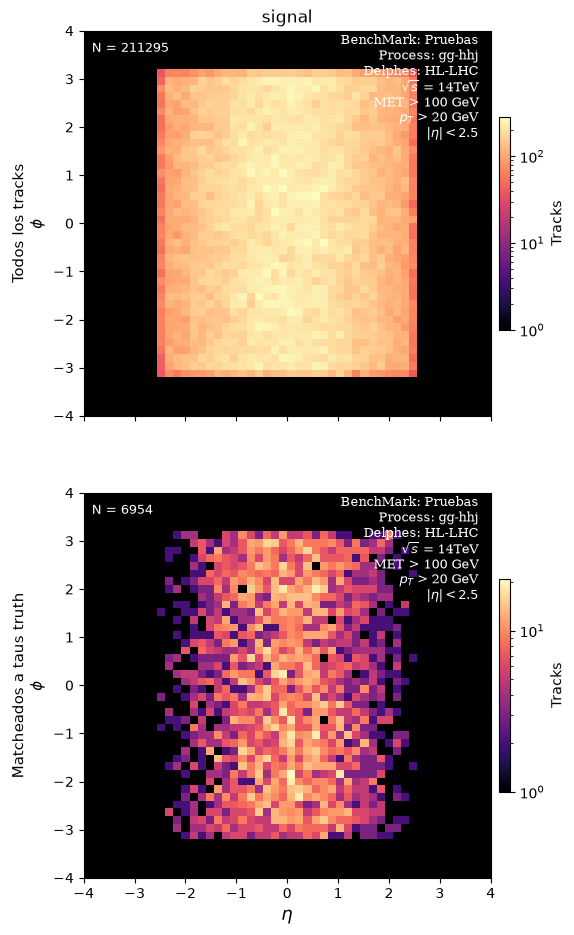

In [24]:
from matplotlib.colors import LogNorm

list_keys = list(rutas.keys())
rango = [[-4, 4], [-4, 4]]

filas = [("Todos los tracks", eta_data,      phi_data),
         ("Matcheados a taus truth", eta_data_taus, phi_data_taus)]

fig, axes = plt.subplots(2, len(list_keys),
                         figsize=(5.5*len(list_keys), 11),
                         sharex=True, sharey=True, squeeze=False)

for r, (titulo_fila, eta_d, phi_d) in enumerate(filas):
    # norma comun a la fila: mismo color = mismo numero de tracks
    vmax = max(np.histogram2d(eta_d[k], phi_d[k], bins=50, range=rango)[0].max()
               for k in list_keys)
    norm = LogNorm(vmin=1, vmax=max(vmax, 2))

    for c, key in enumerate(list_keys):
        ax = axes[r, c]
        x, y = eta_d[key], phi_d[key]
        h = ax.hist2d(x, y, bins=50, range=rango, cmap="magma", norm=norm, cmin=1)

        ax.set_facecolor("black")
        ax.grid(False)
        if r == 0:
            ax.set_title(key, fontsize=12)
        if r == len(filas) - 1:
            ax.set_xlabel(r"$\eta$", fontsize=13)
        ax.text(0.02, 0.97, f"N = {len(x)}", transform=ax.transAxes,
                ha="left", va="top", fontsize=9, color="white")

        ax.text(0.97, 0.995, Data_text_ID_jets, ha="right", va="top",
         fontsize=9, family="DejaVu Serif", transform=ax.transAxes, color="white")

    axes[r, 0].set_ylabel(f"{titulo_fila}\n" + r"$\phi$", fontsize=11)
    fig.colorbar(h[3], ax=axes[r, :].tolist(), label="Tracks",
                 fraction=0.025, pad=0.02)

plt.savefig(f"{selected_data_folder_path_jets}/2D-eta_phi_todos_vs_matched.png", dpi=300)
plt.show()

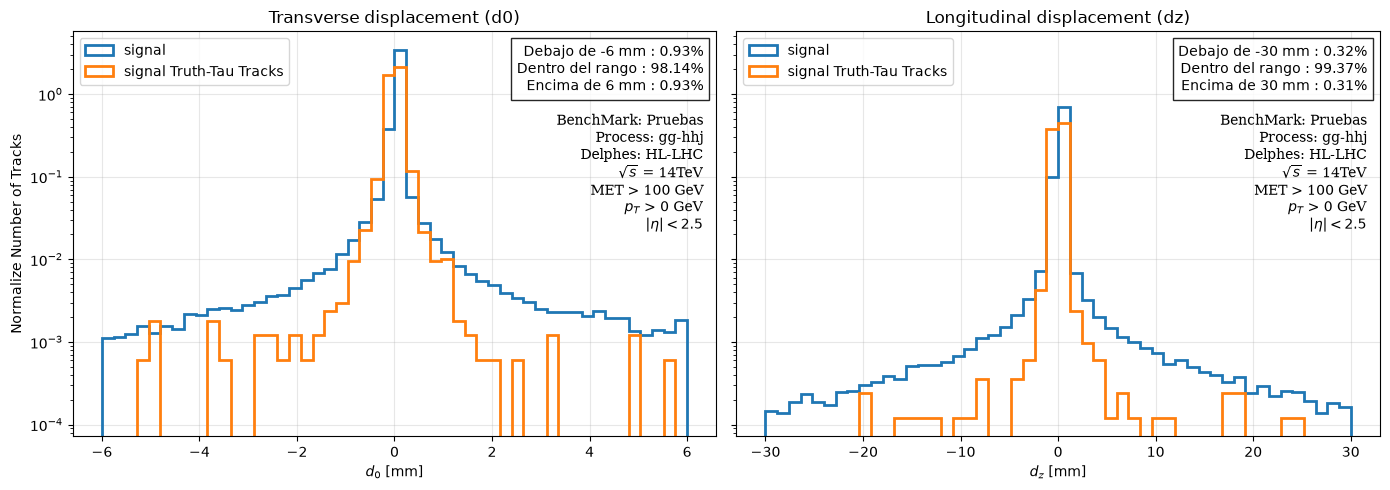

In [25]:
d0_data = {key: ak.to_numpy(ak.flatten(tracks[key].d0)) for key in tracks}
dz_data = {key: ak.to_numpy(ak.flatten(tracks[key].dz)) for key in tracks}

d0_truthtau_tracks = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].d0)) for key in Tracks_truthTaus}
dz_truthtau_tracks = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].dz)) for key in Tracks_truthTaus}

kw = dict(bins=50, density=True, histtype="step", linewidth=2)

lim_inf_d0, lim_sup_d0, p_debajo_d0, p_dentro_d0, p_encima_d0 = calculo_rangos(-6,6, list(d0_data.values()))
lim_inf_dz, lim_sup_dz, p_debajo_dz, p_dentro_dz, p_encima_dz = calculo_rangos(-30,30, list(dz_data.values()))

texto0 = (f"Debajo de {lim_inf_d0} mm : {p_debajo_d0:.2f}%\n"f"Dentro del rango : {p_dentro_d0:.2f}%\n"f"Encima de {lim_sup_d0} mm : {p_encima_d0:.2f}%")
texto1 = (f"Debajo de {lim_inf_dz} mm : {p_debajo_dz:.2f}%\n"f"Dentro del rango : {p_dentro_dz:.2f}%\n"f"Encima de {lim_sup_dz} mm : {p_encima_dz:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14,5), sharey=True)

axes[0].text(0.98, 0.97,texto0,transform=axes[0].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[1].text(0.98, 0.97,texto1,transform=axes[1].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))

for i, (key, d0) in enumerate(d0_data.items()):
        axes[0].hist(d0, range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key}")
        axes[0].hist(d0_truthtau_tracks[key], range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key} Truth-Tau Tracks")

for j, (key, dz) in enumerate(dz_data.items()):
        axes[1].hist(dz, range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key}")
        axes[1].hist(dz_truthtau_tracks[key], range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key} Truth-Tau Tracks")

axes[0].set_xlabel(r"$d_0$ [mm]")
axes[0].set_ylabel("Normalize Number of Tracks")
axes[0].set_yscale('log')
axes[0].set_title('Transverse displacement (d0)')

axes[1].set_xlabel(r"$d_z$ [mm]")
axes[1].set_title('Longitudinal displacement (dz)')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc = 'upper left')
    ax.text(0.98, 0.8, Data_text_ID_tracks, transform=ax.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")
# 
plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Vertex_displacement.png", dpi=300)
plt.show()

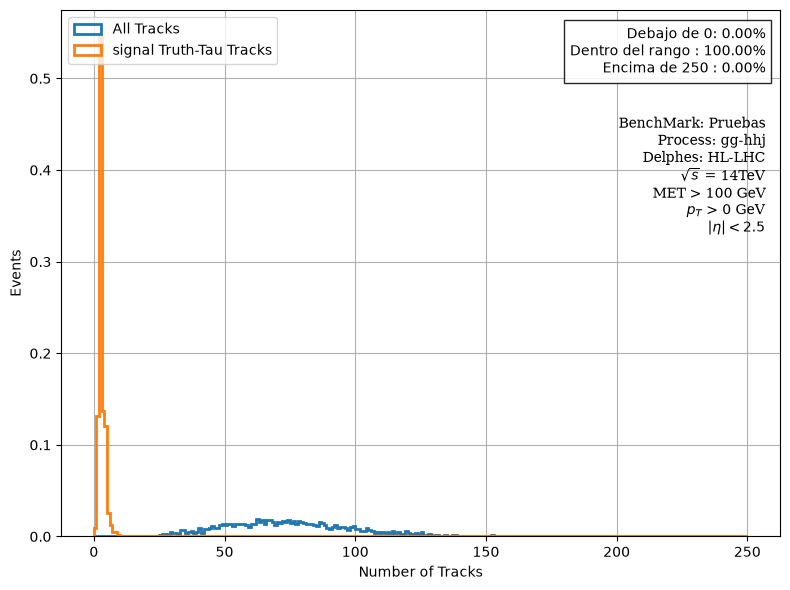

In [26]:
# Numero de Tracks por evento

ntrk_data = {key: ak.to_numpy(ak.num(tracks[key], axis=1)) for key in tracks}
ntrk_truthtau = {key: ak.to_numpy(ak.num(Tracks_truthTaus[key]["tracks_taus"], axis=1)) for key in Tracks_truthTaus}

lim_inf_ntrk, lim_sup_ntrk, p_debajo_ntrk, p_dentro_ntrk, p_encima_ntrk = calculo_rangos(0,250, list(ntrk_data.values()))

texto0 = (f"Debajo de {lim_inf_ntrk}: {p_debajo_ntrk:.2f}%\n"f"Dentro del rango : {p_dentro_ntrk:.2f}%\n"f"Encima de {lim_sup_ntrk} : {p_encima_ntrk:.2f}%")

plt.figure(figsize=(8,6))

plt.text(0.98, 0.97,texto0,transform=plt.gca().transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
plt.text(0.98, 0.8, Data_text_ID_tracks, transform=plt.gca().transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

for i, (key, ntrk) in enumerate(ntrk_data.items()):
        plt.hist(ntrk, bins=250, density=True, range=(lim_inf_ntrk, lim_sup_ntrk), histtype="step", linewidth=2, label=f"All Tracks")
        plt.hist(ntrk_truthtau[key], bins=250, density=True, range=(lim_inf_ntrk, lim_sup_ntrk), histtype="step", linewidth=2, label=f"{key} Truth-Tau Tracks")

plt.xlabel(r"Number of Tracks")
plt.ylabel("Events")
plt.grid()
plt.legend(loc = 'upper left')

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Number_of_Tracks.png", dpi=300)
plt.show()

## Ordered Tracks - GNN entry

In [27]:
def PT_hierachy_50_tracks(tracks_entry, N_MAX = 50):
    tracks_ordenados = {}
    for key, trk in tracks_entry.items():
        orden = ak.argsort(trk.pt, axis=1, ascending=False)
        tracks_ordenados[key] = trk[orden][:, :N_MAX]

    return tracks_ordenados

In [28]:
# tracks sorted by PT, highest first

tracks_ord = PT_hierachy_50_tracks(tracks)

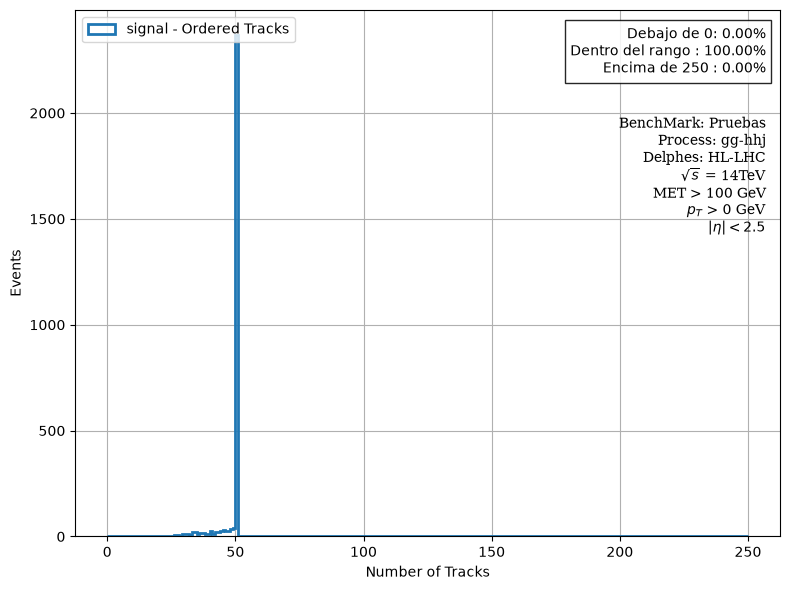

In [29]:
# Cercioro estar tomando hasta 50 Tracks

ntrk_ord_data = {key: ak.to_numpy(ak.num(tracks_ord[key], axis=1)) for key in tracks_ord}

lim_inf_ntrk_ord, lim_sup_ntrk_ord, p_debajo_ntrk_ord, p_dentro_ntrk_ord, p_encima_ntrk_ord = calculo_rangos(0,250, list(ntrk_ord_data.values()))

texto0 = (f"Debajo de {lim_inf_ntrk_ord}: {p_debajo_ntrk_ord:.2f}%\n"f"Dentro del rango : {p_dentro_ntrk_ord:.2f}%\n"f"Encima de {lim_sup_ntrk_ord} : {p_encima_ntrk_ord:.2f}%")

plt.figure(figsize=(8,6))

plt.text(0.98, 0.97,texto0,transform=plt.gca().transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
plt.text(0.98, 0.8, Data_text_ID_tracks, transform=plt.gca().transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

for i, (key, ntrk_ord) in enumerate(ntrk_ord_data.items()):
        plt.hist(ntrk_ord, bins=250, density=False, range=(lim_inf_ntrk_ord, lim_sup_ntrk_ord), histtype="step", linewidth=2, label=f"{key} - Ordered Tracks")
        
plt.xlabel(r"Number of Tracks")
plt.ylabel("Events")
plt.grid()
plt.legend(loc = 'upper left')

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Number_of_Tracks_Ordered.png", dpi=300)
plt.show()

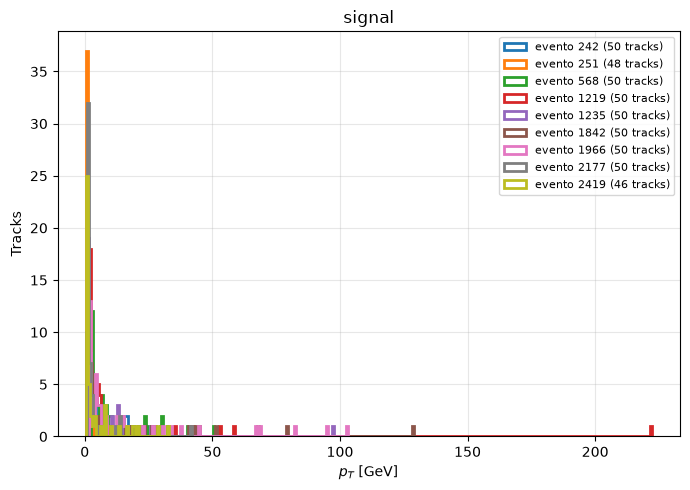

In [30]:
# Distribución de PT por evento de tracks_ord

N_EVENTOS = 9        # eventos aleatorios por muestra
SEED      = 42       # fijo, para que el plot sea reproducible

rng      = np.random.default_rng(SEED)
columnas = list(rutas.keys())

fig, axes = plt.subplots(1, len(columnas), figsize=(7 * len(columnas), 5),
                         sharex=True, sharey=True, squeeze=False)

for i_col, key in enumerate(columnas):
    ax     = axes[0][i_col]
    n_disp = len(tracks_ord[key])
    idxs   = np.sort(rng.choice(n_disp, size=min(N_EVENTOS, n_disp), replace=False))

    for idx in idxs:
        pt = ak.to_numpy(tracks_ord[key][idx].pt)
        pt_max = pt.max()

        nbins = int(pt_max * 1.25)
       
        ax.hist(pt, bins=nbins, histtype="step",
                linewidth=2, label=f"evento {idx} ({len(pt)} tracks)")

    ax.set_title(key)
    ax.set_xlabel(r"$p_T$ [GeV]")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[0][0].set_ylabel("Tracks")

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Tracks_ordered_PT_distribution_per_event.png", dpi=300)
plt.show()

signal: ok 2821/2821  prongs- [ 253 2118  192  205   33]  prongs+ [ 278 2099  214  190   20]


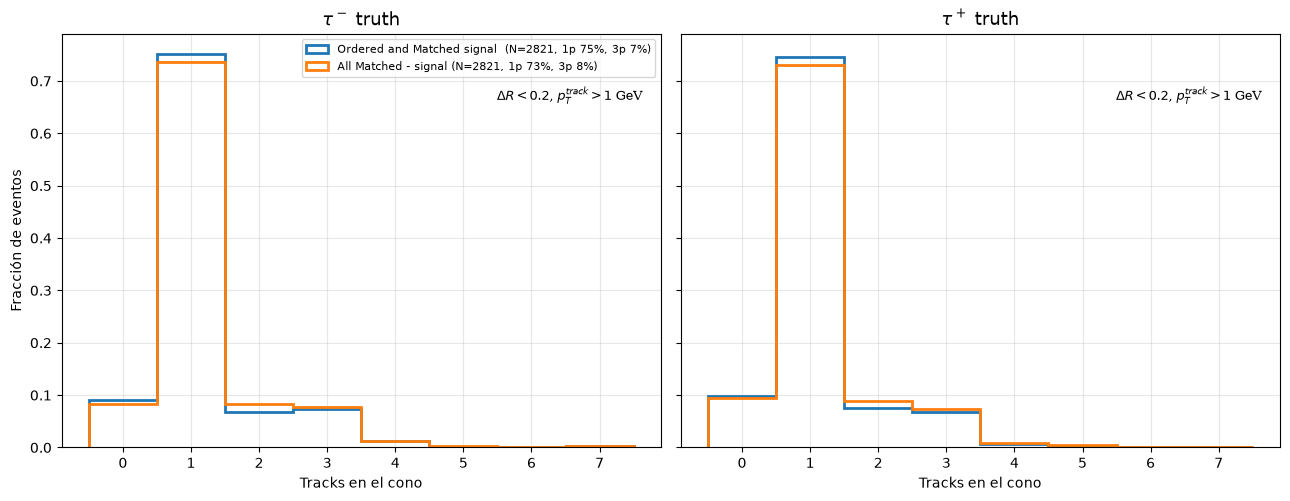

In [31]:
# Los tracks de mayor Pt están asociados a taus truth?

# ---- parámetros ----
DR_TAU   = 0.2    # radio del cono alrededor del tau truth
PT_TRACK = 1    # umbral mínimo de pT de los tracks [GeV]

Ordered_tracks_truthTaus = {key: match_tracks_to_truth_taus(gen[key], tracks_ord[key], DR_TAU, PT_TRACK) for key in gen}

for key, m in Ordered_tracks_truthTaus.items():
    print(f"{key}: ok {ak.sum(m['ok'])}/{len(m['ok'])}  "
          f"prongs- {np.bincount(ak.to_numpy(m['n_m']), minlength=5)[:5]}  "
          f"prongs+ {np.bincount(ak.to_numpy(m['n_p']), minlength=5)[:5]}")

bines = np.arange(-0.5, 8.5, 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), sharey=True)

for ax, campo, lab in [(axes[0], "n_m", r"$\tau^-$ truth"),
                       (axes[1], "n_p", r"$\tau^+$ truth")]:
    for key, m in Ordered_tracks_truthTaus.items():
        a = ak.to_numpy(m[campo])
        ax.hist(a, bins=bines, histtype="step", linewidth=2, density=True,
                label=f"Ordered and Matched {key}  (N={len(a)}, 1p {100*(a==1).mean():.0f}%, "
                      f"3p {100*(a==3).mean():.0f}%)")

    for key, m in Tracks_truthTaus.items():
            a = ak.to_numpy(m[campo])
            ax.hist(a, bins=bines, histtype="step", linewidth=2, density=True,
                    label=f"All Matched - {key} (N={len(a)}, 1p {100*(a==1).mean():.0f}%, "
                          f"3p {100*(a==3).mean():.0f}%)")
            
    ax.text(0.97, 0.87, fr"$\Delta R < {DR_TAU}$, $p_T^{{track}} > {PT_TRACK}$ GeV",
         ha="right", va="top", fontsize=9, family="DejaVu Serif", transform=ax.transAxes)
    ax.set_title(lab, fontsize=13)
    ax.set_xlabel("Tracks en el cono")
    ax.set_xticks(range(0, 8))
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Fracción de eventos")
axes[0].legend(fontsize=8, loc="upper right")

plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.savefig(f"{selected_data_folder_path_tracks}/Prongs_truth_matched_to_ordered_tracks.png", dpi=300)
plt.show()

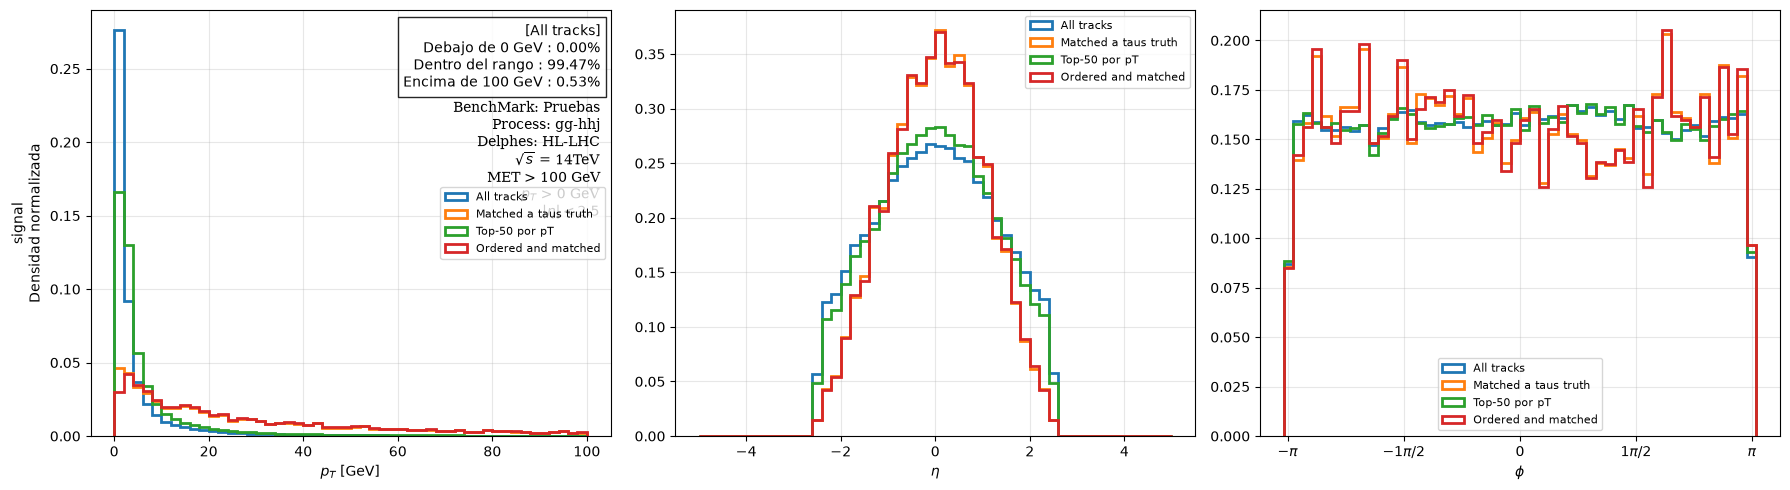

In [32]:
# Que parámetros geométricos y distribuciones cinemáticas tienen estos tracks?

def aplanar(diccionario, campo, sub=None):
    """dict muestra -> array plano. sub: key interna si el valor es un dict (Tracks_truthTaus)."""
    salida = {}
    for key, valor in diccionario.items():
        arr = valor[sub] if sub is not None else valor
        salida[key] = ak.to_numpy(ak.flatten(arr[campo]))
    return salida

def porcentajes(a, lo, hi):
    """Fracciones debajo / dentro / encima del rango que se va a plotear."""
    n = len(a)
    if n == 0:
        return 0.0, 0.0, 0.0
    return (100.0 * np.sum(a < lo) / n,
            100.0 * np.sum((a >= lo) & (a <= hi)) / n,
            100.0 * np.sum(a > hi) / n)

pt_all, eta_all, phi_all = (aplanar(tracks, c)     for c in ("pt", "eta", "phi"))
pt_ord, eta_ord, phi_ord = (aplanar(tracks_ord, c) for c in ("pt", "eta", "phi"))
pt_mat, eta_mat, phi_mat = (aplanar(Tracks_truthTaus, c, sub="tracks_taus") for c in ("pt", "eta", "phi"))
pt_ord_mat, eta_ord_mat, phi_ord_mat = (aplanar(Ordered_tracks_truthTaus, c, sub="tracks_taus") for c in ("pt", "eta", "phi"))


SERIE_REF = "All tracks"      # define el rango y el cuadro de porcentajes
N_MAX = 50

paneles = [
    dict(series={SERIE_REF: pt_all,  "Matched a taus truth": pt_mat, f"Top-{N_MAX} por pT": pt_ord, "Ordered and matched" : pt_ord_mat},
         xlabel=r"$p_T$ [GeV]", rango=(0, 100),     unidad=" GeV", phi=False, loc="center right"),
    dict(series={SERIE_REF: eta_all, "Matched a taus truth": eta_mat, f"Top-{N_MAX} por pT": eta_ord, "Ordered and matched" : eta_ord_mat},
         xlabel=r"$\eta$",      rango=(-5, 5),      unidad="",     phi=False, loc="upper right"),
    dict(series={SERIE_REF: phi_all, "Matched a taus truth": phi_mat, f"Top-{N_MAX} por pT": phi_ord, "Ordered and matched" : phi_ord_mat},
         xlabel=r"$\phi$",      rango=(-3.2, 3.2),  unidad="",     phi=True,  loc="best"),
]

kw = dict(bins=50, density=True, histtype="step", linewidth=2)

filas = list(rutas.keys())
n_filas = len(filas)

# Los limites se calculan UNA vez por columna, sobre todas las muestras,
# para que las filas sean comparables entre si.
limites = []
for panel in paneles:
    lim_inf, lim_sup, *_ = calculo_rangos(*panel["rango"], list(panel["series"][SERIE_REF].values()))
    limites.append((lim_inf, lim_sup))

fig, axes = plt.subplots(n_filas, 3, figsize=(18, 5 * n_filas),
                         sharex="col", sharey="col", squeeze=False)

for i_fila, key in enumerate(filas):
    for i_col, panel in enumerate(paneles):

        ax = axes[i_fila][i_col]
        lim_inf, lim_sup = limites[i_col]

        for nombre_serie, datos in panel["series"].items():
            if key not in datos:
                continue
            ax.hist(datos[key], range=(lim_inf, lim_sup),
                    label=nombre_serie, **kw)

        # porcentajes de ESTA muestra, en la primera columna de cada fila
        if i_col == 0:
            p_debajo, p_dentro, p_encima = porcentajes(
                panel["series"][SERIE_REF][key], lim_inf, lim_sup
            )
            u = panel["unidad"]
            texto = (f"[{SERIE_REF}]\n"
                     f"Debajo de {lim_inf}{u} : {p_debajo:.2f}%\n"
                     f"Dentro del rango : {p_dentro:.2f}%\n"
                     f"Encima de {lim_sup}{u} : {p_encima:.2f}%")
            ax.text(0.98, 0.97, texto, transform=ax.transAxes, ha="right", va="top",
                    bbox=dict(facecolor="white", alpha=0.85))
            ax.set_ylabel(f"{key}\nDensidad normalizada")

        # el ID del dataset y la leyenda, una sola vez (fila superior)
        if i_fila == 0:
            ax.legend(loc=panel["loc"], fontsize=8)
            if i_col == 0:
                ax.text(0.98, 0.79, Data_text_ID_tracks, transform=ax.transAxes,
                        ha="right", va="top", fontsize=10, family="DejaVu Serif")

        # el xlabel solo en la fila de abajo (las columnas comparten eje x)
        if i_fila == n_filas - 1:
            ax.set_xlabel(panel["xlabel"])

        ax.grid(alpha=0.3)

        if panel["phi"]:
            ax.xaxis.set_major_locator(MultipleLocator(np.pi / 2))
            ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Tracks_distributions_ordered_tracks.png", dpi=300)
plt.show()

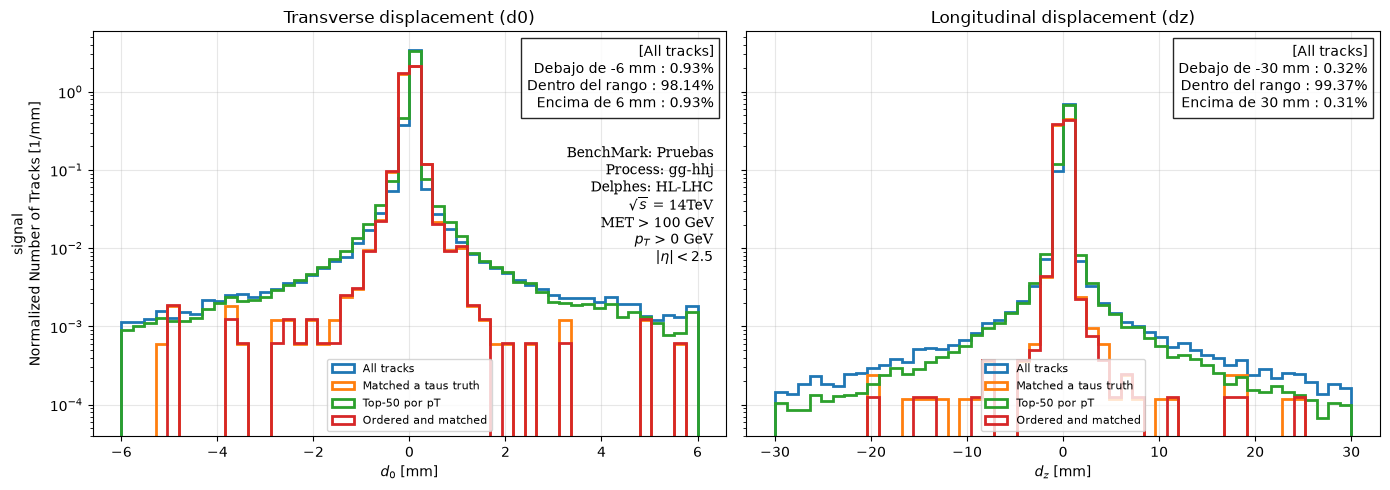

In [33]:
d0_all,  dz_all        = (aplanar(tracks, c)     for c in ("d0", "dz"))
d0_ord,  dz_ord        = (aplanar(tracks_ord, c) for c in ("d0", "dz"))
d0_mat,  dz_mat        = (aplanar(Tracks_truthTaus, c, sub="tracks_taus") for c in ("d0", "dz"))
d0_ord_mat, dz_ord_mat = (aplanar(Ordered_tracks_truthTaus, c, sub="tracks_taus") for c in ("d0", "dz"))

SERIE_REF = "All tracks"      # define el rango y el cuadro de porcentajes

paneles = [
    dict(series={SERIE_REF: d0_all, "Matched a taus truth": d0_mat, f"Top-{N_MAX} por pT": d0_ord, "Ordered and matched": d0_ord_mat},
         xlabel=r"$d_0$ [mm]", titulo="Transverse displacement (d0)",   rango=(-6, 6),   unidad=" mm", loc="lower center"),
    dict(series={SERIE_REF: dz_all, "Matched a taus truth": dz_mat, f"Top-{N_MAX} por pT": dz_ord, "Ordered and matched": dz_ord_mat},
         xlabel=r"$d_z$ [mm]", titulo="Longitudinal displacement (dz)", rango=(-30, 30), unidad=" mm", loc="lower center"),
]

kw = dict(bins=50, density=True, histtype="step", linewidth=2)

filas = list(rutas.keys())
n_filas = len(filas)

# Limites una vez por columna, sobre todas las muestras, para que las filas sean comparables.
limites = []
for panel in paneles:
    lim_inf, lim_sup, *_ = calculo_rangos(*panel["rango"], list(panel["series"][SERIE_REF].values()))
    limites.append((lim_inf, lim_sup))

fig, axes = plt.subplots(n_filas, 2, figsize=(14, 5 * n_filas),
                         sharex="col", sharey=True, squeeze=False)

for i_fila, key in enumerate(filas):
    for i_col, panel in enumerate(paneles):

        ax = axes[i_fila][i_col]
        lim_inf, lim_sup = limites[i_col]

        for nombre_serie, datos in panel["series"].items():
            if key not in datos:
                continue
            ax.hist(datos[key], range=(lim_inf, lim_sup),
                    label=nombre_serie, **kw)

        # porcentajes de ESTA muestra, en las dos columnas: las colas son la fisica
        p_debajo, p_dentro, p_encima = porcentajes(
            panel["series"][SERIE_REF][key], lim_inf, lim_sup
        )
        u = panel["unidad"]
        texto = (f"[{SERIE_REF}]\n"
                 f"Debajo de {lim_inf}{u} : {p_debajo:.2f}%\n"
                 f"Dentro del rango : {p_dentro:.2f}%\n"
                 f"Encima de {lim_sup}{u} : {p_encima:.2f}%")
        ax.text(0.98, 0.97, texto, transform=ax.transAxes, ha="right", va="top",
                bbox=dict(facecolor="white", alpha=0.85))

        if i_col == 0:
            ax.set_ylabel(f"{key}\nNormalized Number of Tracks [1/mm]")

        # titulo, leyenda e ID del dataset una sola vez (fila superior)
        if i_fila == 0:
            ax.set_title(panel["titulo"])
            ax.legend(loc=panel["loc"], fontsize=8)
            if i_col == 0:
                ax.text(0.98, 0.72, Data_text_ID_tracks, transform=ax.transAxes,
                        ha="right", va="top", fontsize=10, family="DejaVu Serif")

        if i_fila == n_filas - 1:
            ax.set_xlabel(panel["xlabel"])

        ax.set_yscale("log")
        ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Vertex_displacement_ordered_tracks.png", dpi=300)
plt.show()

# Criteria

## D0 null

In [34]:
# construyo los tracks con D0 < 1mm

null_D0_tracks = {key: tracks[key][abs(tracks[key].d0) < 1] for key in tracks.keys()}

# los ordeno en pt
null_tracks_ord = PT_hierachy_50_tracks(null_D0_tracks)


# los matcheo con taus_truth
DR_TAU   = 0.2    # radio del cono alrededor del tau truth
PT_TRACK = 1    # umbral mínimo de pT de los tracks [GeV]

Null_Tracks_truthTaus = {key: match_tracks_to_truth_taus(gen[key], null_D0_tracks[key]) for key in gen}

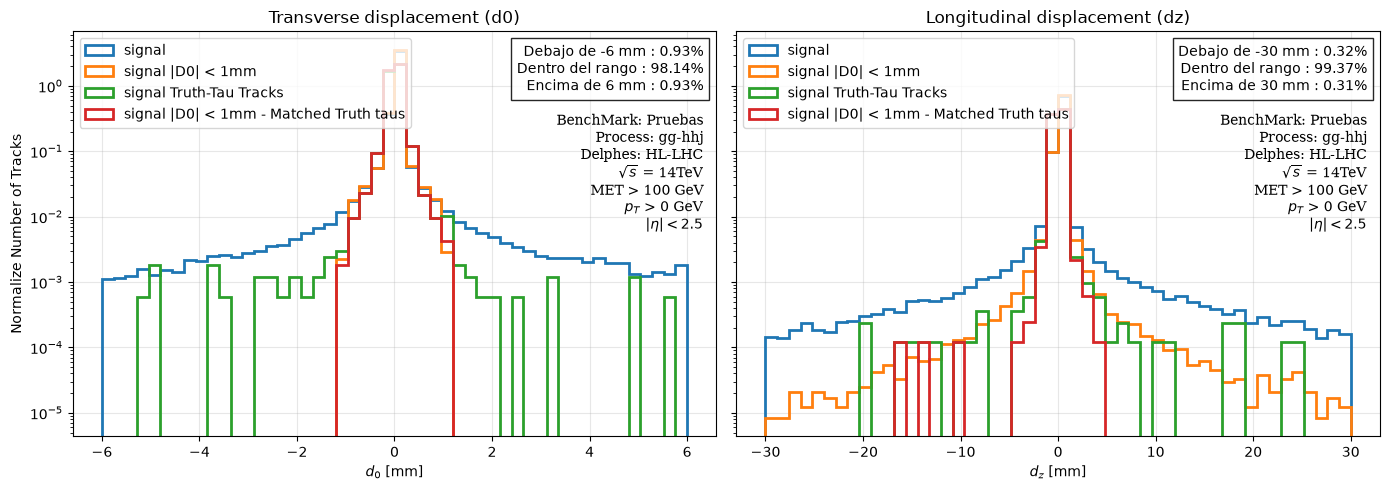

In [35]:
d0_data = {key: ak.to_numpy(ak.flatten(tracks[key].d0)) for key in tracks}
dz_data = {key: ak.to_numpy(ak.flatten(tracks[key].dz)) for key in tracks}

d0_truthtau_tracks = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].d0)) for key in Tracks_truthTaus}
dz_truthtau_tracks = {key: ak.to_numpy(ak.flatten(Tracks_truthTaus[key]["tracks_taus"].dz)) for key in Tracks_truthTaus}

d0_null_tracks = {key: ak.to_numpy(ak.flatten(null_D0_tracks[key].d0)) for key in null_D0_tracks}
dz_null_tracks = {key: ak.to_numpy(ak.flatten(null_D0_tracks[key].dz)) for key in null_D0_tracks}

d0_null_tracks_matched = {key: ak.to_numpy(ak.flatten(Null_Tracks_truthTaus[key]["tracks_taus"].d0)) for key in Null_Tracks_truthTaus}
dz_null_tracks_matched = {key: ak.to_numpy(ak.flatten(Null_Tracks_truthTaus[key]["tracks_taus"].dz)) for key in Null_Tracks_truthTaus}

kw = dict(bins=50, density=True, histtype="step", linewidth=2)

lim_inf_d0, lim_sup_d0, p_debajo_d0, p_dentro_d0, p_encima_d0 = calculo_rangos(-6,6, list(d0_data.values()))
lim_inf_dz, lim_sup_dz, p_debajo_dz, p_dentro_dz, p_encima_dz = calculo_rangos(-30,30, list(dz_data.values()))

texto0 = (f"Debajo de {lim_inf_d0} mm : {p_debajo_d0:.2f}%\n"f"Dentro del rango : {p_dentro_d0:.2f}%\n"f"Encima de {lim_sup_d0} mm : {p_encima_d0:.2f}%")
texto1 = (f"Debajo de {lim_inf_dz} mm : {p_debajo_dz:.2f}%\n"f"Dentro del rango : {p_dentro_dz:.2f}%\n"f"Encima de {lim_sup_dz} mm : {p_encima_dz:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(14,5), sharey=True)

axes[0].text(0.98, 0.97,texto0,transform=axes[0].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[1].text(0.98, 0.97,texto1,transform=axes[1].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))

for i, (key, d0) in enumerate(d0_data.items()):
        axes[0].hist(d0, range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key}")
        axes[0].hist(d0_null_tracks[key], range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key} |D0| < 1mm")
        axes[0].hist(d0_truthtau_tracks[key], range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key} Truth-Tau Tracks")
        axes[0].hist(d0_null_tracks_matched[key], range=(lim_inf_d0, lim_sup_d0), **kw, label=f"{key} |D0| < 1mm - Matched Truth taus") 

for j, (key, dz) in enumerate(dz_data.items()):
        axes[1].hist(dz, range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key}")
        axes[1].hist(dz_null_tracks[key], range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key} |D0| < 1mm")
        axes[1].hist(dz_truthtau_tracks[key], range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key} Truth-Tau Tracks")
        axes[1].hist(dz_null_tracks_matched[key], range=(lim_inf_dz, lim_sup_dz), **kw, label=f"{key} |D0| < 1mm - Matched Truth taus") 

axes[0].set_xlabel(r"$d_0$ [mm]")
axes[0].set_ylabel("Normalize Number of Tracks")
axes[0].set_yscale('log')
axes[0].set_title('Transverse displacement (d0)')

axes[1].set_xlabel(r"$d_z$ [mm]")
axes[1].set_title('Longitudinal displacement (dz)')

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(loc = 'upper left')
    ax.text(0.98, 0.8, Data_text_ID_tracks, transform=ax.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")
# 
plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Vertex_displacement_D0_null_criteria.png", dpi=300)
plt.show()

Distribuciones cinemáticas de estos tracks:

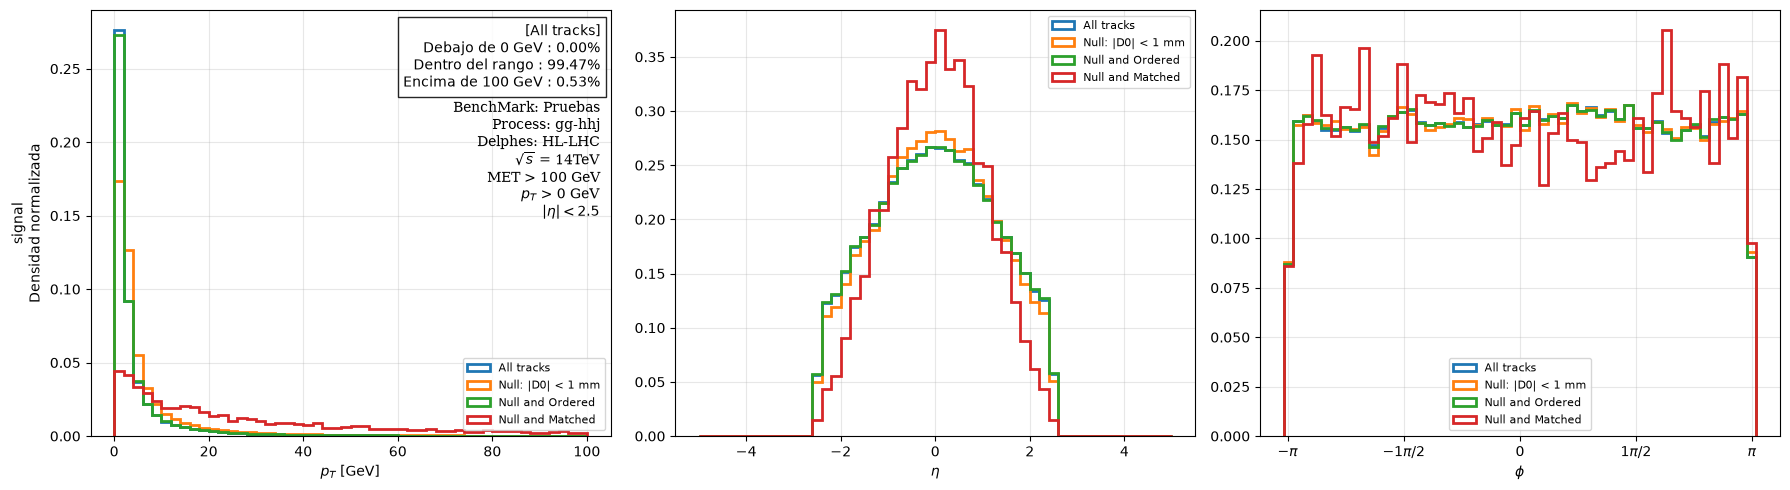

In [36]:
# Que parámetros geométricos y distribuciones cinemáticas tienen estos tracks?

pt_all, eta_all, phi_all = (aplanar(tracks, c)     for c in ("pt", "eta", "phi"))
pt_ord, eta_ord, phi_ord = (aplanar(null_D0_tracks, c) for c in ("pt", "eta", "phi"))
pt_mat, eta_mat, phi_mat = (aplanar(null_tracks_ord, c) for c in ("pt", "eta", "phi"))
pt_ord_mat, eta_ord_mat, phi_ord_mat = (aplanar(Null_Tracks_truthTaus, c, sub="tracks_taus") for c in ("pt", "eta", "phi"))


SERIE_REF = "All tracks"      # define el rango y el cuadro de porcentajes
N_MAX = 50

paneles = [
    dict(series={SERIE_REF: pt_all,  "Null: |D0| < 1 mm": pt_mat, f"Null and Ordered": pt_ord, "Null and Matched" : pt_ord_mat},
         xlabel=r"$p_T$ [GeV]", rango=(0, 100),     unidad=" GeV", phi=False, loc="lower right"),

    dict(series={SERIE_REF: eta_all, "Null: |D0| < 1 mm": eta_mat, f"Null and Ordered": eta_ord, "Null and Matched" : eta_ord_mat},
         xlabel=r"$\eta$",      rango=(-5, 5),      unidad="",     phi=False, loc="upper right"),

    dict(series={SERIE_REF: phi_all, "Null: |D0| < 1 mm": phi_mat, f"Null and Ordered": phi_ord, "Null and Matched" : phi_ord_mat},
         xlabel=r"$\phi$",      rango=(-3.2, 3.2),  unidad="",     phi=True,  loc="best"),
]

kw = dict(bins=50, density=True, histtype="step", linewidth=2)

filas = list(rutas.keys())
n_filas = len(filas)

# Los limites se calculan UNA vez por columna, sobre todas las muestras,
# para que las filas sean comparables entre si.
limites = []
for panel in paneles:
    lim_inf, lim_sup, *_ = calculo_rangos(*panel["rango"], list(panel["series"][SERIE_REF].values()))
    limites.append((lim_inf, lim_sup))

fig, axes = plt.subplots(n_filas, 3, figsize=(18, 5 * n_filas),
                         sharex="col", sharey="col", squeeze=False)

for i_fila, key in enumerate(filas):
    for i_col, panel in enumerate(paneles):

        ax = axes[i_fila][i_col]
        lim_inf, lim_sup = limites[i_col]

        for nombre_serie, datos in panel["series"].items():
            if key not in datos:
                continue
            ax.hist(datos[key], range=(lim_inf, lim_sup),
                    label=nombre_serie, **kw)

        # porcentajes de ESTA muestra, en la primera columna de cada fila
        if i_col == 0:
            p_debajo, p_dentro, p_encima = porcentajes(
                panel["series"][SERIE_REF][key], lim_inf, lim_sup
            )
            u = panel["unidad"]
            texto = (f"[{SERIE_REF}]\n"
                     f"Debajo de {lim_inf}{u} : {p_debajo:.2f}%\n"
                     f"Dentro del rango : {p_dentro:.2f}%\n"
                     f"Encima de {lim_sup}{u} : {p_encima:.2f}%")
            ax.text(0.98, 0.97, texto, transform=ax.transAxes, ha="right", va="top",
                    bbox=dict(facecolor="white", alpha=0.85))
            ax.set_ylabel(f"{key}\nDensidad normalizada")

        # el ID del dataset y la leyenda, una sola vez (fila superior)
        if i_fila == 0:
            ax.legend(loc=panel["loc"], fontsize=8)
            if i_col == 0:
                ax.text(0.98, 0.79, Data_text_ID_tracks, transform=ax.transAxes,
                        ha="right", va="top", fontsize=10, family="DejaVu Serif")

        # el xlabel solo en la fila de abajo (las columnas comparten eje x)
        if i_fila == n_filas - 1:
            ax.set_xlabel(panel["xlabel"])

        ax.grid(alpha=0.3)

        if panel["phi"]:
            ax.xaxis.set_major_locator(MultipleLocator(np.pi / 2))
            ax.xaxis.set_major_formatter(FuncFormatter(pi_formatter))

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Tracks_distributions_ordered_tracks.png", dpi=300)
plt.show()

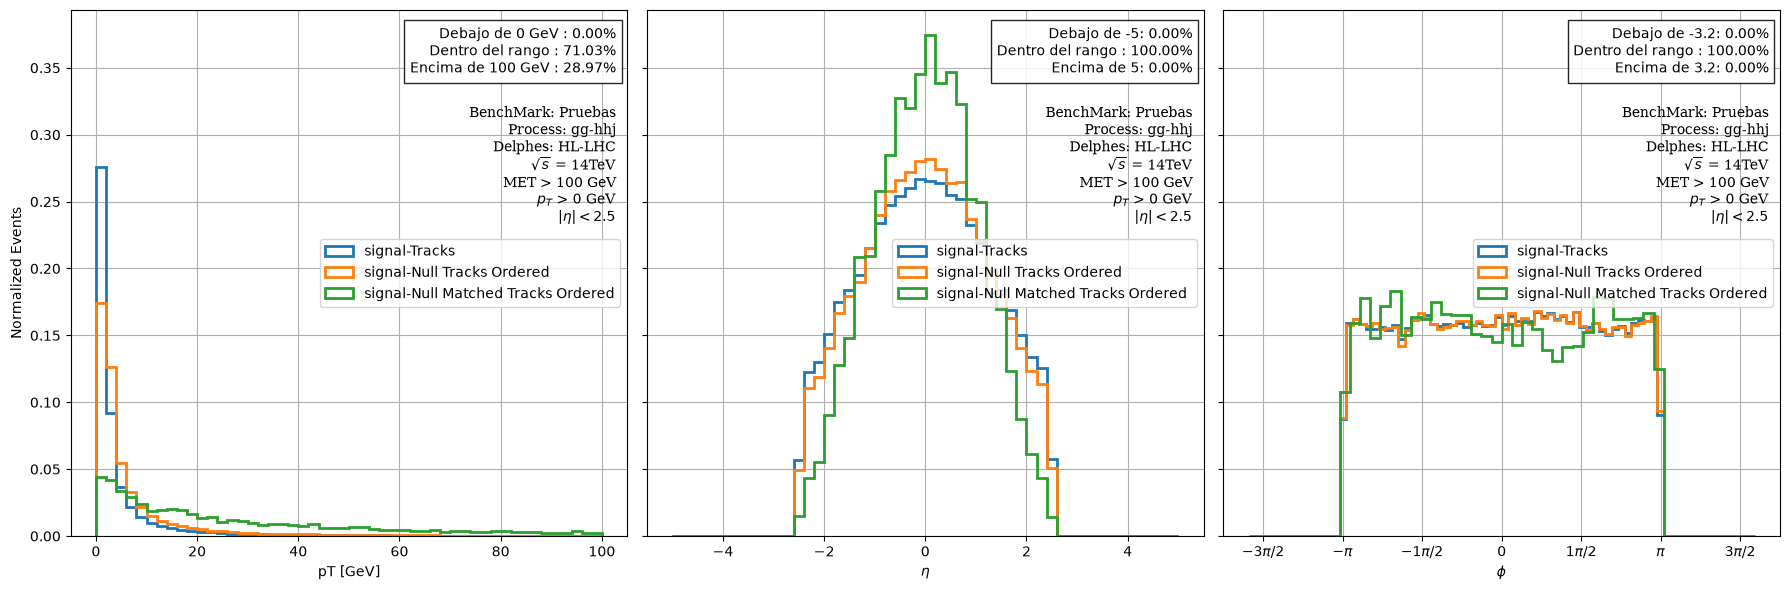

In [37]:
pt_data = {key: ak.to_numpy(ak.flatten(tracks[key].pt)) for key in tracks}
eta_data = {key: ak.to_numpy(ak.flatten(tracks[key].eta)) for key in tracks}
phi_data = {key: ak.to_numpy(ak.flatten(tracks[key].phi)) for key in tracks}

pt_null_ord = {key: ak.to_numpy(ak.flatten(null_tracks_ord[key].pt)) for key in null_tracks_ord}
eta_null_ord = {key: ak.to_numpy(ak.flatten(null_tracks_ord[key].eta)) for key in null_tracks_ord}
phi_null_ord = {key: ak.to_numpy(ak.flatten(null_tracks_ord[key].phi)) for key in null_tracks_ord}

pt_null_matched_ord = {key: ak.to_numpy(ak.flatten(Null_Tracks_truthTaus[key]["tracks_taus"].pt)) for key in Null_Tracks_truthTaus}
eta_null_matched_ord = {key: ak.to_numpy(ak.flatten(Null_Tracks_truthTaus[key]["tracks_taus"].eta)) for key in Null_Tracks_truthTaus}
phi_null_matched_ord = {key: ak.to_numpy(ak.flatten(Null_Tracks_truthTaus[key]["tracks_taus"].phi)) for key in Null_Tracks_truthTaus}

lim_inf_pt, lim_sup_pt, p_debajo_pt, p_dentro_pt, p_encima_pt = calculo_rangos(0, 100, list(MET_data.values()))
lim_inf_eta, lim_sup_eta, p_debajo_eta, p_dentro_eta, p_encima_eta = calculo_rangos(-5,5, list(eta_data.values()))
lim_inf_phi, lim_sup_phi, p_debajo_phi, p_dentro_phi, p_encima_phi = calculo_rangos(-3.2,3.2, list(phi_data.values()))

texto_pt = (f"Debajo de {lim_inf_pt} GeV : {p_debajo_pt:.2f}%\n"f"Dentro del rango : {p_dentro_pt:.2f}%\n"f"Encima de {lim_sup_pt} GeV : {p_encima_pt:.2f}%")
texto_eta = (f"Debajo de {lim_inf_eta}: {p_debajo_eta:.2f}%\n"f"Dentro del rango : {p_dentro_eta:.2f}%\n"f"Encima de {lim_sup_eta}: {p_encima_eta:.2f}%")
texto_phi = (f"Debajo de {lim_inf_phi}: {p_debajo_phi:.2f}%\n"f"Dentro del rango : {p_dentro_phi:.2f}%\n"f"Encima de {lim_sup_phi}: {p_encima_phi:.2f}%")

labels = [r"LQ - Tracks", r"BG - Tracks", r"SM - Tracks"]
kw = dict(bins=50, density=True, histtype="step", linewidth=2)

fig, axes = plt.subplots(1, 3, figsize=(18,6), sharey=True)

for i, (key, pt) in enumerate(pt_data.items()):
        axes[0].hist(pt, range=(lim_inf_pt, lim_sup_pt), **kw, label=f"{key}-Tracks")
        axes[0].hist(pt_null_ord[key], range=(lim_inf_pt, lim_sup_pt), **kw, label=f"{key}-Null Tracks Ordered")
        axes[0].hist(pt_null_matched_ord[key], range=(lim_inf_pt, lim_sup_pt), **kw, label=f"{key}-Null Matched Tracks Ordered")

for j, (key, eta) in enumerate(eta_data.items()):
        axes[1].hist(eta, range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key}-Tracks")
        axes[1].hist(eta_null_ord[key], range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key}-Null Tracks Ordered")
        axes[1].hist(eta_null_matched_ord[key], range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key}-Null Matched Tracks Ordered ")

for k, (key, phi) in enumerate(phi_data.items()):
        axes[2].hist(phi, range=(lim_inf_phi, lim_sup_phi), **kw, label=f"{key}-Tracks")
        axes[2].hist(phi_null_ord[key], range=(lim_inf_phi, lim_sup_phi), **kw, label=f"{key}-Null Tracks Ordered")
        axes[2].hist(phi_null_matched_ord[key], range=(lim_inf_eta, lim_sup_eta), **kw, label=f"{key}-Null Matched Tracks Ordered")
        
axes[0].text(0.98, 0.97,texto_pt,transform=axes[0].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[0].set_ylabel("Normalized Events")
axes[0].set_xlabel("pT [GeV]")
axes[0].legend(loc = 'center right')

axes[1].text(0.98, 0.97,texto_eta,transform=axes[1].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[1].set_xlabel(r"$\eta$")
axes[1].legend(loc = 'center right')

axes[2].text(0.98, 0.97,texto_phi,transform=axes[2].transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))
axes[2].xaxis.set_major_locator(MultipleLocator(np.pi / 2))
axes[2].xaxis.set_major_formatter(FuncFormatter(pi_formatter))
axes[2].set_xlabel(r"$\phi$")
axes[2].legend(loc = 'center right')

for ax in axes:
        ax.grid()
        ax.text(0.98, 0.82, Data_text_ID_tracks, transform=ax.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")


plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_tracks}/Tracks_distributions.png", dpi=300)
plt.show()


# Jets Analysis

In [38]:
def build_taus_and_bjets(jets_input):
    
    taus, bjets, NEvents, NTaus, NBjets = {}, {}, {}, {}, {}
    for key, d in jets_input.items():
        taus[key], bjets[key], NEvents[key], NTaus[key], NBjets[key] = Taus_and_bjets(d)
    return taus, bjets, NEvents, NTaus, NBjets

def build_selected_pairs(taus, bjets):
    out = {}
    for key in taus:
        t1, t2, bb1, bb2, tc, bc = kinematic_hierarchical_order(taus[key], bjets[key])
        out[key] = {"tau1": t1, "tau2": t2, "b1": bb1, "b2": bb2,
                    "taus": tc, "bjets": bc}
    return out


def build_observables(sel):
    obs = {}
    for key, s in sel.items():
        t1, t2, bb1, bb2 = s["tau1"], s["tau2"], s["b1"], s["b2"]
        tup_tt, tup_bb, tup_hh = PT_and_IM_of_products(t1, t2, bb1, bb2)

        obs[key] = {
            "m_tautau": tup_tt[0],  "m_bb": tup_bb[0],  "m_hh": tup_hh[0],
            "pt_tautau": tup_tt[1], "pt_bb": tup_bb[1], "pt_hh": tup_hh[1],
            "dR_tautau": t1.deltaR(t2),
            "dR_bb":     bb1.deltaR(bb2),
            "dR_hh": (t1+t2).deltaR(bb1 + bb2)
        }
    return obs


taus, bjets, NEvents, NTaus, NBjets = build_taus_and_bjets(jets)    # Selecciono los Taus y Bs de cada Dataset
Selection_dictionary = build_selected_pairs(taus, bjets)            # Recorto a eventos con al menos 2 Taus y 2 Bs, y los ordeno por Pt
Observables = build_observables(Selection_dictionary)               # Calculo los observables de cada par de Taus y Bs seleccionados

ncols = len(Observables)


In [39]:
etiquetas = {"signal": "Señal", "standardmodel": "Modelo Estándar", "background": "Fondo"}

def doubletag_events(j):
    dt = (j['TauTag'] == 1) & (j['BTag'] == 1)
    n_dt = int(ak.sum(ak.num(j[dt], axis=1) > 0))
    n_ev = len(j)
    return n_dt, 100 * n_dt / n_ev if n_ev else 0.0

lineas = [Data_text_ID_jets, ""]
lineas.append(f"{'Muestra':<18} {'Generados':>10} {'Pasan MET':>10} {'Acept. MET':>11} "
              f"{'Sel. 2t+2b':>11} {'Acept.':>8} {'Acept. tot.':>12} "
              f"{'Ev. doble tag':>14} {'% doble':>8}")
lineas.append("-" * 112)

for key in all_data:
    n_gen = len(all_data[key])
    n_met = len(jets[key])
    n_sel = len(Selection_dictionary[key]["taus"])

    acc_met = 100 * n_met / n_gen if n_gen else 0.0
    acc_sel = 100 * n_sel / n_met if n_met else 0.0
    acc_tot = 100 * n_sel / n_gen if n_gen else 0.0

    n_dt, pct_dt = doubletag_events(jets[key])

    lineas.append(f"{key:<18} {n_gen:>10} {n_met:>10} {acc_met:>10.2f}% "
                  f"{n_sel:>11} {acc_sel:>7.2f}% {acc_tot:>11.2f}% "
                  f"{n_dt:>14} {pct_dt:>7.2f}%")

texto = "\n".join(lineas)
print(texto)
_ = (Path(selected_data_folder_path_jets) / "cutflow.txt").write_text(texto + "\n")

BenchMark: Pruebas
Process: gg-hhj
Delphes: HL-LHC
$\sqrt{s}$ = 14TeV
MET > 100 GeV
$p_T$ > 20 GeV
$|\eta| < 2.5$

Muestra             Generados  Pasan MET  Acept. MET  Sel. 2t+2b   Acept.  Acept. tot.  Ev. doble tag  % doble
----------------------------------------------------------------------------------------------------------------
signal                   9736       2821      28.97%          94    3.33%        0.97%            165    5.85%


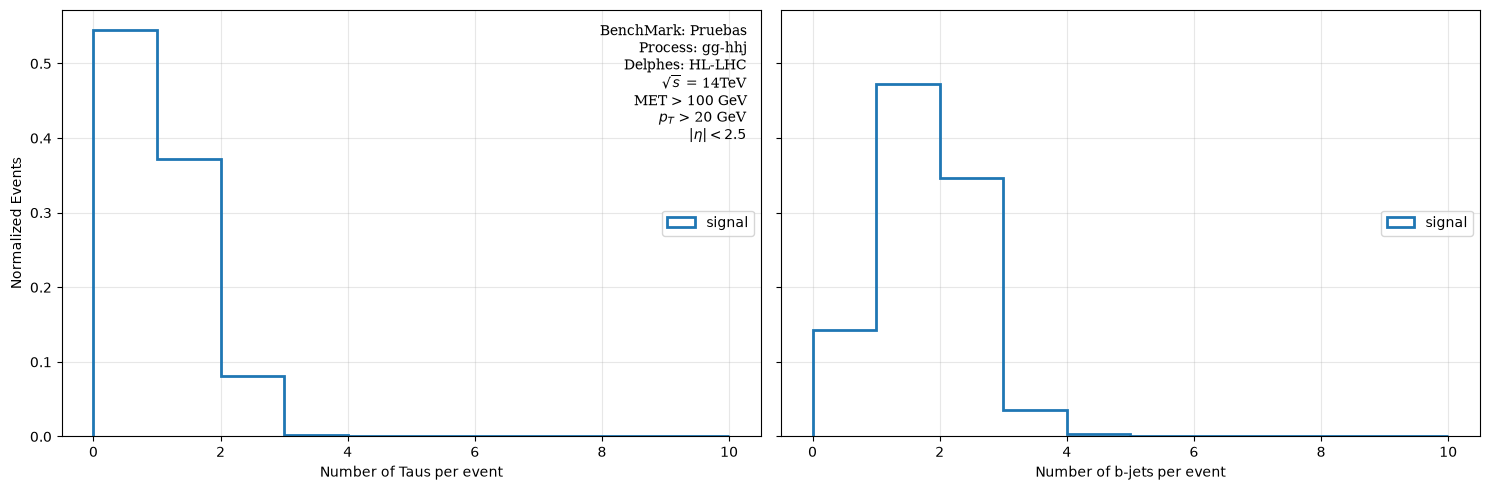

In [40]:
lim_inf_Ntaus, lim_sup_Ntaus, p_debajo_Ntaus, p_dentro_Ntaus, p_encima_Ntaus = calculo_rangos(0, 10, list(NTaus.values()))
lim_inf_Nbjets, lim_sup_Nbjets, p_debajo_Nbjets, p_dentro_Nbjets, p_encima_Nbjets = calculo_rangos(0, 10, list(NBjets.values()))

texto_Ntaus = (f"Debajo de {lim_inf_Ntaus} GeV : {p_debajo_Ntaus:.2f}%\n"f"Dentro del rango : {p_dentro_Ntaus:.2f}%\n"f"Encima de {lim_sup_Ntaus} GeV : {p_encima_Ntaus:.2f}%")
texto_Nbjets = (f"Debajo de {lim_inf_Nbjets} GeV : {p_debajo_Nbjets:.2f}%\n"f"Dentro del rango : {p_dentro_Nbjets:.2f}%\n"f"Encima de {lim_sup_Nbjets} GeV : {p_encima_Nbjets:.2f}%")

kw = dict(bins=10, density=True, histtype="step", linewidth=2)

fig, axes = plt.subplots(1, 2, figsize=(15,5), sharey=True)

axes[0].text(0.98, 0.97, Data_text_ID_jets, transform=axes[0].transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

for key, arr in NTaus.items():
    axes[0].hist(ak.to_numpy(arr), range=(lim_inf_Ntaus, lim_sup_Ntaus), **kw, label=key)
    
axes[0].set_xlabel(r"Number of Taus per event")
axes[0].set_ylabel("Normalized Events")
axes[0].legend(loc = "center right")
axes[0].grid(alpha=0.3)

for key, arr in NBjets.items():
    axes[1].hist(ak.to_numpy(arr), range=(lim_inf_Nbjets, lim_sup_Nbjets), **kw, label=key)
axes[1].set_xlabel(r"Number of b-jets per event")
axes[1].legend(loc = "center right")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_jets}/Taus&Bjets_in_events.png", dpi=300)
plt.show()

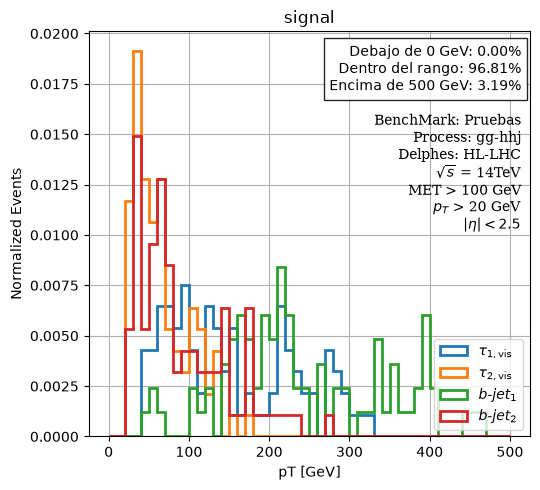

In [41]:
tau1_pt_data = {key: ak.to_numpy(Selection_dictionary[key]["tau1"].pt) for key in Selection_dictionary}
tau2_pt_data = {key: ak.to_numpy(Selection_dictionary[key]["tau2"].pt) for key in Selection_dictionary}
bjet1_pt_data = {key: ak.to_numpy(Selection_dictionary[key]["b1"].pt) for key in Selection_dictionary}
bjet2_pt_data = {key: ak.to_numpy(Selection_dictionary[key]["b2"].pt) for key in Selection_dictionary}

pt_all = {key: [tau1_pt_data[key],tau2_pt_data[key],bjet1_pt_data[key],bjet2_pt_data[key]]
          for key in Selection_dictionary}

rangos = {key: calculo_rangos(0, 500, pt_all[key]) for key in pt_all}

textos_rangos_pt = {}
for key, (li, ls, p_deb, p_den, p_enc) in rangos.items():
    textos_rangos_pt[key] = (f"Debajo de {li} GeV: {p_deb:.2f}%\n"
                   f"Dentro del rango: {p_den:.2f}%\n"
                   f"Encima de {ls} GeV: {p_enc:.2f}%")
    
labels = [r"$\tau_{1, \text{vis}}$", r"$\tau_{2, \text{vis}}$", r"$b\text{-}jet_1$", r"$b\text{-}jet_2$"]
kw = dict(bins=50, range=(0,500), density=True, histtype="step", linewidth=2)

fig, axes = plt.subplots(1, len(Observables.keys()), figsize=(5.5*ncols,5), sharey=True, squeeze=False)
axes = axes[0]
for i, (key) in enumerate(Selection_dictionary.keys()):
        axes[i].hist(tau1_pt_data[key], **kw, label=labels[0])
        axes[i].hist(tau2_pt_data[key], **kw, label=labels[1])
        axes[i].hist(bjet1_pt_data[key], **kw, label=labels[2])
        axes[i].hist(bjet2_pt_data[key], **kw, label=labels[3])
        axes[i].set_title(fr"{key}")
        axes[i].set_xlabel("pT [GeV]")
        axes[i].grid()
        axes[i].legend(loc = 'lower right')
        axes[i].text(0.98, 0.97, textos_rangos_pt[key], transform=axes[i].transAxes,
                ha="right", va="top", bbox=dict(facecolor="white", alpha=0.85))

axes[0].text(0.98, 0.8, Data_text_ID_jets, transform=axes[0].transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")
axes[0].set_ylabel("Normalized Events")

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_jets}/pt_distribution.png", dpi=300)
plt.show()

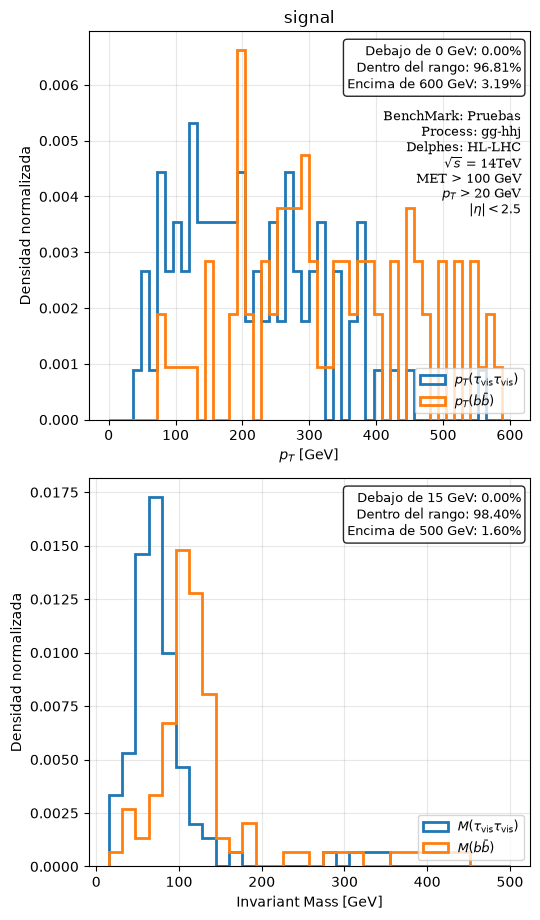

In [42]:
filas = [
    ("pt_tautau", "pt_bb", (0, 600),  50, r"$p_T$ [GeV]",
     r"$p_T(\tau_{\mathrm{vis}}\tau_{\mathrm{vis}})$", r"$p_T(b\bar{b})$"),
    ("m_tautau",  "m_bb",  (15, 500), 30, r"Invariant Mass [GeV]",
     r"$M(\tau_{\mathrm{vis}}\tau_{\mathrm{vis}})$", r"$M(b\bar{b})$"),
]

fig, axes = plt.subplots(2, len(Observables.keys()), figsize=(5.5*ncols, 10), sharey='row',squeeze=False)
for r, (k_tt, k_bb, (lo, hi), nbins, xlabel, lab_tt, lab_bb) in enumerate(filas):
    for c, key in enumerate(Observables):
        ax = axes[r, c]
        li, ls, p_deb, p_den, p_enc = calculo_rangos(lo, hi, [Observables[key][k_tt], Observables[key][k_bb]])

        kw = dict(bins=nbins, density=True, range=(li, ls), histtype="step", linewidth=2)
        ax.hist(ak.to_numpy(Observables[key][k_tt]), label=lab_tt, **kw)
        ax.hist(ak.to_numpy(Observables[key][k_bb]), label=lab_bb, **kw)

        ax.set_xlabel(xlabel)
        ax.legend(loc="lower right", fontsize=9)
        ax.grid(alpha=0.3)

        txt = (f"Debajo de {li} GeV: {p_deb:.2f}%\n"
               f"Dentro del rango: {p_den:.2f}%\n"
               f"Encima de {ls} GeV: {p_enc:.2f}%")
        ax.text(0.98, 0.97, txt, transform=ax.transAxes, ha="right", va="top",
                fontsize=9, bbox=dict(boxstyle="round", facecolor="white", alpha=0.85))

        if r == 0:
            ax.set_title(fr'{key}')

axes[0, 0].set_ylabel("Densidad normalizada")
axes[1, 0].set_ylabel("Densidad normalizada")

axes[0, 0].text(0.98, 0.80, Data_text_ID_jets, transform=axes[0, 0].transAxes, ha="right", va="top",
         fontsize=9, family="DejaVu Serif")

fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(f"{selected_data_folder_path_jets}/pT_and_IM_pairs.png", dpi=300)
plt.show()

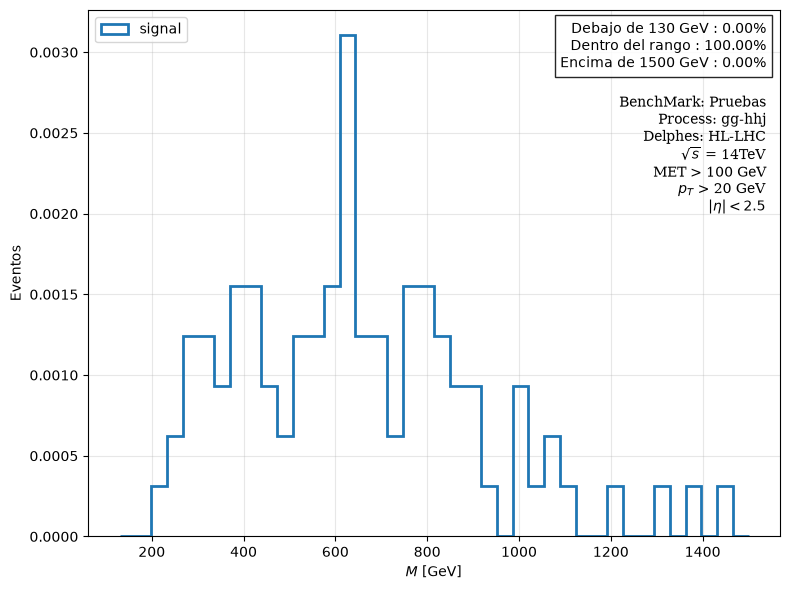

In [43]:
Higgs_mass = {key: ak.to_numpy(Observables[key]["m_hh"]) for key in Observables}

lim_inf_mhh, lim_sup_mhh, p_debajo_mhh, p_dentro_mhh, p_encima_mhh = calculo_rangos(130,1500, list(Higgs_mass.values()))

texto_Higgs = (f"Debajo de {lim_inf_mhh} GeV : {p_debajo_mhh:.2f}%\n"f"Dentro del rango : {p_dentro_mhh:.2f}%\n"f"Encima de {lim_sup_mhh} GeV : {p_encima_mhh:.2f}%")

plt.figure(figsize=(8,6))

plt.text(0.98, 0.84, Data_text_ID_jets, transform=plt.gca().transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

plt.text(0.98, 0.98,texto_Higgs,transform=plt.gca().transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))

for key, arr in Higgs_mass.items():
    plt.hist(ak.to_numpy(arr), bins=40, density=True, range=(lim_inf_mhh, lim_sup_mhh), histtype="step", linewidth=2, label=fr'{key}')

plt.xlabel(r"$M$ [GeV]")
plt.ylabel("Eventos")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_jets}/InvariantMass_distribution.png", dpi=300)
plt.show()

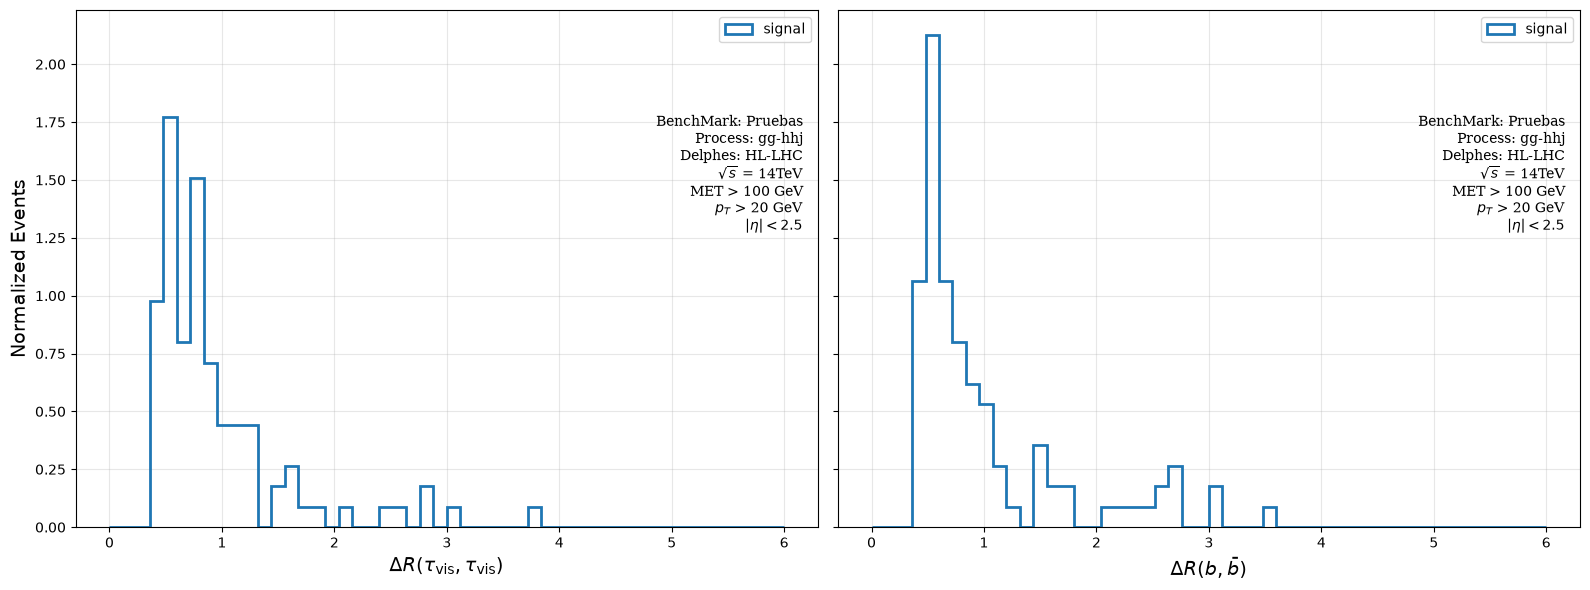

In [44]:
DeltaR_TT = {key: ak.to_numpy(Observables[key]["dR_tautau"]) for key in Observables}
DeltaR_BB = {key: ak.to_numpy(Observables[key]["dR_bb"]) for key in Observables}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,6), sharey=True)

ax1.text(0.98, 0.80, Data_text_ID_jets, transform=ax1.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

ax2.text(0.98, 0.80, Data_text_ID_jets, transform=ax2.transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

kw = dict(bins=50,range=(0,6),histtype="step", density = True, linewidth=2)

# ==========================================================
# Primer gráfico
# ==========================================================

for key, arr in DeltaR_TT.items():
    ax1.hist(arr, **kw, label=fr"{key}")

ax1.set_xlabel(r"$\Delta R(\tau_{\text{vis}},\tau_{\text{vis}})$", fontsize=14)
ax1.set_ylabel("Normalized Events", fontsize=14)
ax1.grid(alpha=0.3)
ax1.legend(fontsize=10)

# ==========================================================
# Segundo gráfico
# ==========================================================

for key, arr in DeltaR_BB.items():
    ax2.hist(arr, **kw, label=fr"{key}")

ax2.set_xlabel(r"$\Delta R(b,\bar{b})$", fontsize=14)
ax2.grid(alpha=0.3)
ax2.legend(fontsize=10)

# ==========================================================
# Ajustes finales
# ==========================================================

plt.tight_layout()

plt.savefig(f"{selected_data_folder_path_jets}/DeltaR_distribution.png", dpi=300)

plt.show()

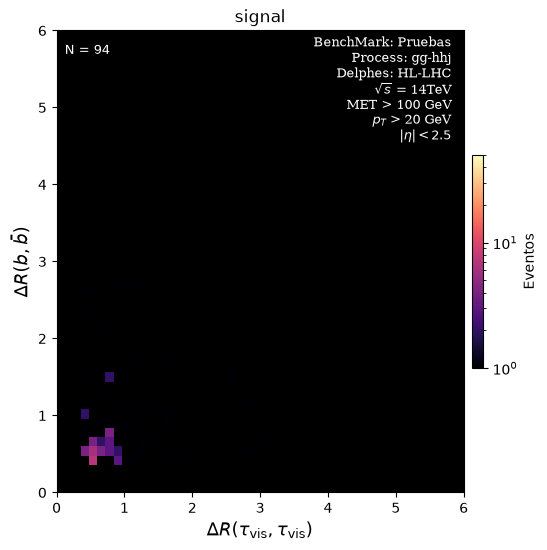

In [45]:
list_keys = list(DeltaR_TT.keys())
rango = [[0, 6], [0, 6]]
norm  = LogNorm(vmin=1, vmax=50)

fig, axes = plt.subplots(1, len(list_keys), figsize=(5.5*len(list_keys), 6),
                         sharex=True, sharey=True, squeeze=False)
axes = axes[0]

for ax, key in zip(axes, list_keys):
    x = ak.to_numpy(DeltaR_TT[key])
    y = ak.to_numpy(DeltaR_BB[key])
    h = ax.hist2d(x, y, bins=50, range=rango, cmap="magma", norm = norm, cmin=1)

    ax.set_facecolor("black")
    ax.set_title(key, fontsize=12)
    ax.set_xlabel(r"$\Delta R(\tau_{\rm vis},\tau_{\rm vis})$", fontsize=13)
    ax.text(0.02, 0.97, f"N = {len(x)}", transform=ax.transAxes,
            ha="left", va="top", fontsize=9, color="white")
    ax.text(0.97, 0.99, Data_text_ID_jets, ha="right", va="top", transform=ax.transAxes,
         fontsize=9, family="DejaVu Serif", color = 'white')

axes[0].set_ylabel(r"$\Delta R(b,\bar{b})$", fontsize=13)

fig.colorbar(h[3], ax=axes, label="Eventos", fraction=0.025, pad=0.02)

fig.savefig(f"{selected_data_folder_path_jets}/2D-DeltaR_por_muestra.png", dpi=300)
plt.show()

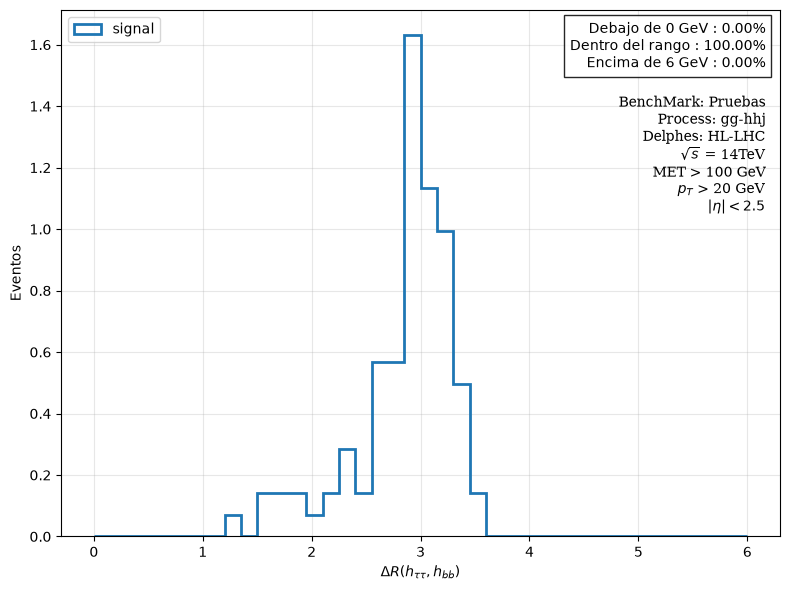

In [46]:
DR_of_Higgses = {key: ak.to_numpy(Observables[key]["dR_hh"]) for key in Observables}

lim_inf_dRhh, lim_sup_dRhh, p_debajo_dRhh, p_dentro_dRhh, p_encima_dRhh = calculo_rangos(0, 6, list(DR_of_Higgses.values()))

texto_Higgs = (f"Debajo de {lim_inf_dRhh} GeV : {p_debajo_dRhh:.2f}%\n"f"Dentro del rango : {p_dentro_dRhh:.2f}%\n"f"Encima de {lim_sup_dRhh} GeV : {p_encima_dRhh:.2f}%")

plt.figure(figsize=(8,6))

plt.text(0.98, 0.84, Data_text_ID_jets, transform=plt.gca().transAxes,
        ha="right", va="top", fontsize=10, family="DejaVu Serif")

plt.text(0.98, 0.98,texto_Higgs,transform=plt.gca().transAxes,ha="right",va="top",bbox=dict(facecolor="white", alpha=0.85))

for key, arr in DR_of_Higgses.items():
    plt.hist(ak.to_numpy(arr), bins=40, density=True, range=(lim_inf_dRhh, lim_sup_dRhh), histtype="step", linewidth=2, label=fr'{key}')

plt.xlabel(r"$\Delta R(h_{\tau \tau}, h_{bb})$")
plt.ylabel("Eventos")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(f"{selected_data_folder_path_jets}/DR_Htautau_Hbb.png", dpi=300)
plt.show()

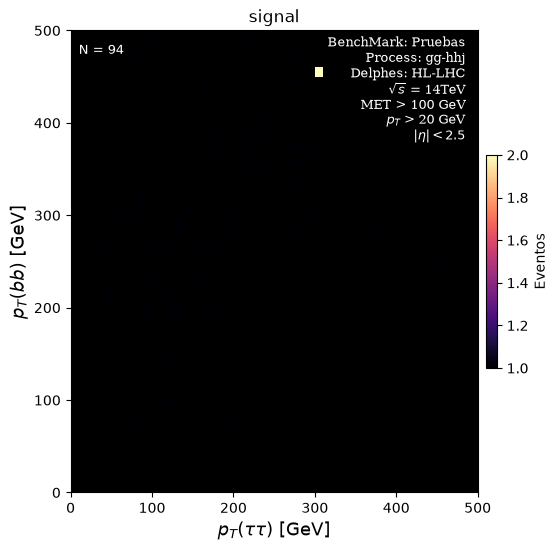

In [47]:
pT_h_tautau = {key: ak.to_numpy(Observables[key]["pt_tautau"]) for key in Observables}
pt_h_bb = {key: ak.to_numpy(Observables[key]["pt_bb"]) for key in Observables}

rango = [[0, 500], [0, 500]]
# norm  = LogNorm(vmin=1, vmax=50)

fig, axes = plt.subplots(1, len(list_keys), figsize=(5.5*len(list_keys), 6),
                         sharex=True, sharey=True, squeeze=False)
axes = axes[0]

for ax, key in zip(axes, list_keys):
    x = ak.to_numpy(pT_h_tautau[key])
    y = ak.to_numpy(pt_h_bb[key])
    h = ax.hist2d(x, y, bins=50, range=rango, cmap="magma", cmin=1)

    ax.set_facecolor("black")
    ax.set_title(key, fontsize=12)
    ax.set_xlabel(r"$p_T(\tau \tau)$ [GeV]", fontsize=13)
    ax.text(0.02, 0.97, f"N = {len(x)}", transform=ax.transAxes,
            ha="left", va="top", fontsize=9, color="white")
    ax.text(0.97, 0.99, Data_text_ID_jets, ha="right", va="top", transform=ax.transAxes,
         fontsize=9, family="DejaVu Serif", color = 'white')

axes[0].set_ylabel(r"$p_T(bb)$ [GeV]", fontsize=13)

fig.colorbar(h[3], ax=axes, label="Eventos", fraction=0.025, pad=0.02)

fig.savefig(f"{selected_data_folder_path_jets}/2D-PT_hpair_distribution.png", dpi=300)
plt.show()